# bottle：通常学習とランダム回転学習の比較

**主目的：回転させない元のbottleテスト画像で、ランダム回転学習が異常検知AUROCを改善するか確認する。**

- A：正常画像をそのまま使用する通常学習。
- B：同じ正常画像を使うたびに、$[0,360)$ の連続角度で回転するランダム回転学習。
- 両条件をHybrid CNN＋FC、同じ初期重み・画像順・バッチ構成・6,700更新・更新ごとのβで比較する。
- 補助評価として、元と同じ83枚をランダム回転した検査画像も使う。

モデル選定は先送りし、当面はHybridを継続する。Deep5・固定回転・反復拡張・Sparse VAEは今回の比較に混ぜない。
**コード作成・静的確認のみ。アシスタントはコード・構文テスト・学習・評価・描画を実行していない。**
実行はユーザーが行う。初期値 `RUN_FULL_TRAINING=True` のため、上から実行すると2モデルの正式学習を開始する。
学習済みの今回のモデルで評価を再開する場合は、設定セルの案内に従う。途中の学習の継続再開は実装しない。

回転画像の準備には高解像度での加工時間がかかる。重み・ログ・入出力配列・図は新規フォルダへ保存し、過去の結果を上書きしない。


In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
from pathlib import Path
from io import BytesIO
from datetime import datetime
from zoneinfo import ZoneInfo
import csv
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
import uuid
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
from skimage.metrics import structural_similarity as ssim

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
    if (p/'memory/memory.md').is_file() and (p/'data/bottle').is_dir()),None)
if ROOT is None:raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')
OUTPUT_BASE=ROOT/'saved_models/bottle_random_rotation_20261119'
RUN_FULL_TRAINING=True
TRAINING_RUN_ID=None  # 読み込み時だけ完了済みフォルダ名を指定。Noneなら設定が一致する最新の完了済み学習。
SEED=42
SAMPLER_SEED=SEED+1000
AUGMENTATION_SEED=SEED+2000
CONDITIONS=('A_normal','B_random')
LABELS={'A_normal':'A：通常学習','B_random':'B：ランダム回転'}
COLORS={'A_normal':'#526b8e','B_random':'darkorange'}
CATEGORY_LABELS={'good':'正常','broken_large':'大きな破損','broken_small':'小さな破損','contamination':'汚れ・異物'}
SCENARIOS={'unrotated':'回転なし（主評価）','random_rotated':'ランダム回転（補助評価）'}
CROP_SIZE=820
INPUT_SIZE=128
LATENT_DIM=64
BATCH_SIZE=32
TARGET_UPDATES=6700
WARMUP_UPDATES=3350
BETA_MAX=1.0
LEARNING_RATE=0.001
DEVICE=torch.device('cpu')
EVAL_BATCH_SIZE=32
TOP_K=130
ASSIGNMENT_SEEDS=(42,43,44,45,46)
REPRESENTATIVE_SEED=42  # 図用に事前指定。結果を見て選ばない。
TEST_ANGLE_CANDIDATES=np.arange(1,360,dtype=int)  # 0度なし、各画像に1角度
VISUAL_PATHS=None  # 例：['good/000.png','broken_small/000.png']。Noneなら種類ごとに選択。
MAX_IMAGES_PER_CATEGORY=1  # Noneなら全83枚。可視化だけの設定で評価対象は変わらない。
VISUAL_CASES=[('unrotated',-1),('random_rotated',42)]

torch.set_num_threads(min(4,max(1,torch.get_num_threads())))
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
available_fonts={f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic','Meiryo','MS Gothic','Noto Sans CJK JP','IPAexGothic']:
    if font in available_fonts:plt.rcParams['font.family']=font;break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size':11,'axes.unicode_minus':False,'figure.dpi':100})
def read_json(path):return json.loads(path.read_text(encoding='utf-8'))
def write_json(path,value):path.write_text(json.dumps(value,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
def sha256(path):return hashlib.sha256(path.read_bytes()).hexdigest()
def object_hash(value):return hashlib.sha256(json.dumps(value,ensure_ascii=False,sort_keys=True).encode('utf-8')).hexdigest()
def tensor_hash(value):return hashlib.sha256(value.detach().cpu().contiguous().numpy().tobytes()).hexdigest()
def new_id():return datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:8]
def seed_everything(seed):
    random.seed(int(seed));np.random.seed(int(seed));torch.manual_seed(int(seed))
    if torch.cuda.is_available():torch.cuda.manual_seed_all(int(seed))
def copy_cpu_state(model):return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def state_digest(state):
    h=hashlib.sha256()
    for key,value in state.items():
        h.update(key.encode('utf-8')+str(value.dtype).encode('ascii'))
        h.update(value.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
VERSIONS={k:importlib.metadata.version(k) for k in ['torch','numpy','pandas','Pillow','scikit-image','matplotlib']}

MODEL_DEFINITION_SHA='546d83343d03107deffc7f46c4b34c4996f419f807f0a799d524a28931e4f7a2'


## 1. データと前処理

正常学習209枚。テストは正常20枚、大きな破損20枚、小さな破損22枚、汚れ・異物21枚の計83枚。
学習と評価の元画像を記録し、テストを学習や途中モデルの選択には使わない。

全ての画像を**中央820×820→LANCZOSで128×128→白黒→float32・0〜1**とする。
回転を行う場合だけ、820の高解像度で最近傍補間・サイズ維持の回転を行い、空いた部分を白（RGB各255）で埋めてから縮小する。
反射パディングは行わず、過去のbottle用コードと同じ白埋め方式にする。torchvisionはimportせずPillowを直接使う。

回転の補間・サイズ維持・白埋め・縮小の順序は、過去のbottleの820での回転処理に合わせる。今回は固定角度ではなくランダム角度で学習する。
保存設定を白埋め版として区別し、反射補完の過去実行は読み込まない。既存の実験フォルダは変更しない。
変更前の関数がカーネルに残らないよう、修正後はカーネルを再起動して上から実行する。
図表の名称は「ランダム回転」とし、補完方法は設定・再現情報に記録する。


In [2]:
def final_transform(image):
    return image.resize((128,128),resample=Image.Resampling.LANCZOS).convert('L')

def to_tensor(image):
    if image.mode != 'L':
        raise ValueError('白黒化したLモード画像を指定してください。')
    pixels = np.array(image,dtype=np.uint8,copy=True)
    return torch.from_numpy(pixels).unsqueeze(0).to(dtype=torch.float32).div(255)

def rotate_bottle(image,angle):
    # 過去のbottle用TF.rotate(..., NEAREST, expand=False, fill=255)に対応するPillow処理。
    # 隅へボトルの模様を複製せず、回転で空いた部分を白で埋める。
    if image.mode!='RGB':raise ValueError('RGB画像を指定してください。')
    if angle==0:return image.copy()
    return image.rotate(float(angle),resample=Image.Resampling.NEAREST,
        expand=False,center=None,fillcolor=(255,255,255))


def center_crop(image):
    width,height=image.size
    if min(width,height)<CROP_SIZE:raise ValueError(f'中央切り出しサイズより小さい画像：{image.size}')
    # torchvision CenterCropのPIL経路と同じ丸め。bottleの900×900なら左右上下一律40。
    left=int(round((width-CROP_SIZE)/2.0));top=int(round((height-CROP_SIZE)/2.0))
    return image.crop((left,top,left+CROP_SIZE,top+CROP_SIZE))

def read_images(directory,is_test):
    paths=sorted(directory.glob('*/*.png') if is_test else directory.glob('*.png'),
        key=lambda p:p.relative_to(directory).as_posix())
    if not paths:raise FileNotFoundError(directory)
    images=[];records=[]
    for path in paths:
        raw=path.read_bytes()
        with Image.open(BytesIO(raw)) as im:
            size=im.size;image=center_crop(im.convert('RGB')).copy()
        tensor=to_tensor(final_transform(image))
        relative=path.relative_to(directory).as_posix()
        category=path.parent.name if is_test else 'good'
        if category not in CATEGORY_LABELS:raise ValueError(category)
        records.append({'repo_path':path.relative_to(ROOT).as_posix(),'relative_path':relative,
            'category':category,'category_ja':CATEGORY_LABELS[category],'true_label':int(category!='good'),
            'source_size':list(size),'crop_size':[CROP_SIZE,CROP_SIZE],
            'file_sha256':hashlib.sha256(raw).hexdigest(),
            'cropped_rgb_sha256':hashlib.sha256(np.asarray(image).tobytes()).hexdigest(),
            'preprocessed_sha256':tensor_hash(tensor)})
        images.append(image)
    return images,records

assert INPUT_SIZE==128 and CROP_SIZE==820 and BATCH_SIZE==32
assert TARGET_UPDATES==6700 and WARMUP_UPDATES==3350 and BETA_MAX==1
train_images,train_manifest=read_images(ROOT/'data/bottle/train/good',False)
test_images,test_manifest=read_images(ROOT/'data/bottle/test',True)
assert len(train_images)==209 and len(test_images)==83
image_table=pd.DataFrame(test_manifest)
counts=image_table.category.value_counts().to_dict()
assert counts=={'good':20,'broken_large':20,'broken_small':22,'contamination':21}
assert not {r['repo_path'] for r in train_manifest}&{r['repo_path'] for r in test_manifest}
train_base=torch.stack([to_tensor(final_transform(im)) for im in train_images])
test_base=torch.stack([to_tensor(final_transform(im)) for im in test_images])
assert train_base.shape==(209,1,128,128) and test_base.shape==(83,1,128,128)
display(pd.DataFrame([{'テスト種類':CATEGORY_LABELS[k],'枚数':counts[k]} for k in CATEGORY_LABELS]))
print('学習画像数：',len(train_images),'／両条件の1周の更新数：',math.ceil(len(train_images)/BATCH_SIZE))


,テスト種類,枚数
0,正常,20
1,大きな破損,20
2,小さな破損,22
3,汚れ・異物,21


学習画像数： 209 ／両条件の1周の更新数： 7


### 学習入力の見本

Aは元画像1枚だけを左上に表示。Bは同じ元画像に対するランダム回転5例。
表示専用の乱数なので、後の学習の角度抽選や画像順には影響しない。
Bも1周209枚であり、10倍の固定データセットは作らない。画像を使うたびに角度を抽選する。


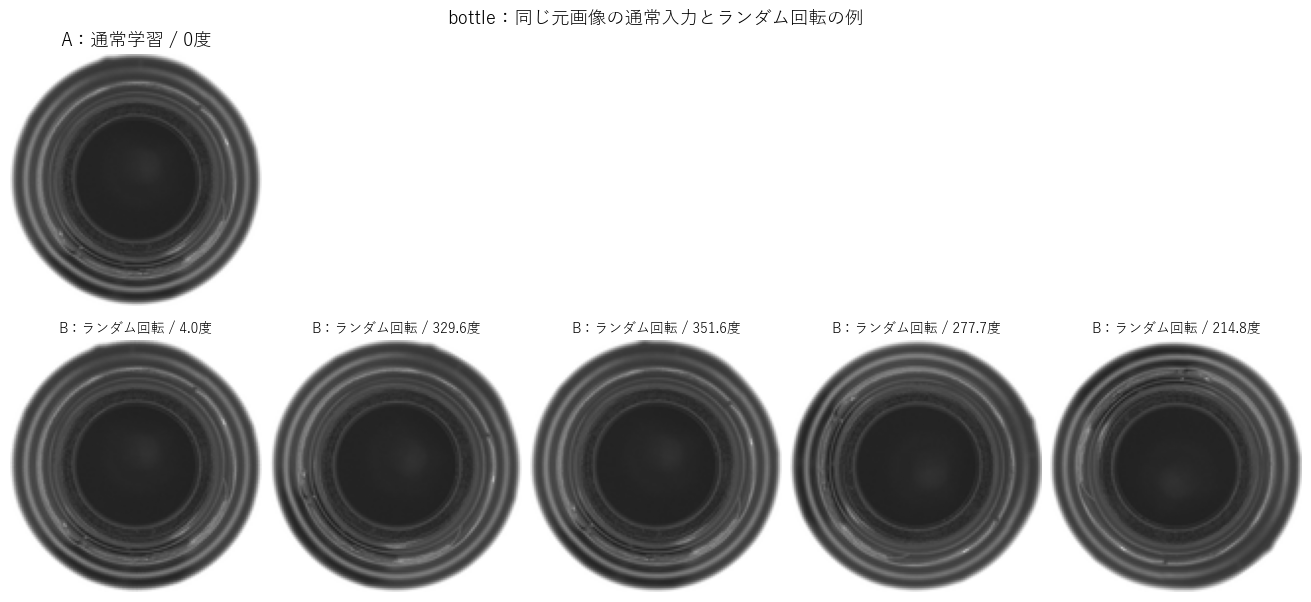

In [3]:
preview_rng=np.random.default_rng(SEED+3000)
preview_angles=preview_rng.uniform(0.0,360.0,size=5)
fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
for ax in axes.flat:ax.axis('off')
axes[0,0].imshow(train_base[0,0],cmap='gray',vmin=0,vmax=1);axes[0,0].set_title('A：通常学習 / 0度')
for col,angle in enumerate(preview_angles):
    tensor=to_tensor(final_transform(rotate_bottle(train_images[0],float(angle))))
    axes[1,col].imshow(tensor[0],cmap='gray',vmin=0,vmax=1);axes[1,col].set_title(f'B：ランダム回転 / {angle:.1f}度',fontsize=10)
fig.suptitle('bottle：同じ元画像の通常入力とランダム回転の例')
plt.show();plt.close(fig)


## 2. モデルと損失

直近のtransistor比較と同じHybrid CNN＋FC（潜在64、log分散は−10〜10に制限）。
学習時は潜在変数をサンプリングし、評価時は平均μから復元する。

$$L=\sum_{b=1}^{B}\sum_{p=1}^{16384}(x_{bp}-\hat x_{bp})^2
+\beta(t)\sum_{b=1}^{B}\frac12\sum_{i=1}^{64}
(\mu_{bi}^2+\exp(v_{bi})-1-v_{bi})$$

$v=\log\sigma^2$。復元項は画素SSE、KLは潜在次元で合計、両項ともバッチについて合計。
学習曲線には画像枚数で割った値を表示する。後の復元品質の補助評価MSEとは区別する。

$$\beta(t)=\min\left(1,\frac{t-1}{3350-1}\right),\quad t=1,\ldots,6700$$

過去の階段状βや異なる初期重みの結果との差を、今回の回転効果として扱わない。


In [4]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar


In [5]:
def binary_roc_curve(y_true, scores):
    labels = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or labels.shape != scores.shape:
        raise ValueError('ラベルとスコアは同じ長さの1次元配列にしてください。')
    if not np.isfinite(scores).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('スコアは有限値、ラベルは0または1である必要があります。')
    positives = int((labels == 1).sum())
    negatives = int((labels == 0).sum())
    if not positives or not negatives:
        raise ValueError('正常と異常の両方が必要です。')
    order = np.argsort(-scores, kind='stable')
    ordered_scores = scores[order]
    ordered_labels = labels[order]
    ends = np.r_[np.flatnonzero(np.diff(ordered_scores)), len(scores) - 1]
    true_positives = np.cumsum(ordered_labels)[ends]
    false_positives = (ends + 1) - true_positives
    fpr = np.r_[0.0, false_positives / negatives]
    tpr = np.r_[0.0, true_positives / positives]
    thresholds = np.r_[np.inf, ordered_scores[ends]]
    return fpr, tpr, thresholds

def binary_auroc(y_true, scores):
    fpr, tpr, _ = binary_roc_curve(y_true, scores)
    return float(np.trapezoid(tpr, fpr))

assert binary_auroc([0,0,1,1], [0.1,0.2,0.8,0.9]) == 1.0
assert binary_auroc([0,0,1,1], [0.9,0.8,0.2,0.1]) == 0.0
assert binary_auroc([0,0,1,1], [0.5,0.5,0.5,0.5]) == 0.5



def verify_auroc(y,scores):
    value=binary_auroc(y,scores)
    normal=scores[y==0]; abnormal=scores[y==1]
    rank=((abnormal[:,None]>normal).sum()+0.5*(abnormal[:,None]==normal).sum())/(len(normal)*len(abnormal))
    assert np.isclose(value,rank,atol=1e-12)
    return value

def score_loaded_model(model,images):
    model.eval()
    reconstructed = np.empty((len(images),128,128),dtype=np.float32)
    error_maps = np.empty_like(reconstructed)
    scores = np.empty(len(images),dtype=np.float64)
    with torch.inference_mode():
        for start in range(0,len(images),EVAL_BATCH_SIZE):
            x = images[start:start+EVAL_BATCH_SIZE].to(DEVICE)
            output,_,_ = model(x,sample=False)
            assert torch.isfinite(output).all()
            for local in range(len(x)):
                index = start+local
                a = x[local,0].cpu().numpy()
                b = output[local,0].cpu().numpy()
                _,ssim_map = ssim(a,b,data_range=1.0,win_size=11,full=True)
                error = 1.0-ssim_map
                assert np.isfinite(error).all()
                reconstructed[index] = b
                error_maps[index] = error
                scores[index] = np.sort(error.ravel())[::-1][:TOP_K].mean()
    return scores,reconstructed,error_maps


def reconstruction_metrics(inputs,reconstructed):
    mse=np.mean((inputs[:,0].numpy()-reconstructed)**2,axis=(1,2))
    similarity=np.array([ssim(a,b,data_range=1.0,win_size=11) for a,b in zip(inputs[:,0].numpy(),reconstructed)])
    return mse,similarity


## 3. 新規2モデルを同じ画像順・更新数で学習する

両条件とも1周209枚、バッチ32（最後17枚）、6,700更新。元画像の順序とバッチ境界を共通にする。
Bの角度用乱数は、データのシャッフル・潜在変数のサンプリングとは別の乱数系列を使う。
同じ初期重みから学習し、元画像の提示順と実際の角度を保存する。
重み・バッファ・ログを混ぜず、条件ごとに新しいモデルとAdamを作る。

完了済みの今回のモデルを使う場合は、設定を `RUN_FULL_TRAINING=False` とし、
`TRAINING_RUN_ID='完了したフォルダ名'` を指定する。Noneなら同じ条件の最新の完了済み学習を読む。
元画像・設定・構造・βのハッシュが一致することを確認し、学習をせずに評価へ進める。


In [6]:
def beta_at_update(update):
    if not 1<=update<=TARGET_UPDATES:raise ValueError('更新番号が範囲外です。')
    return float(BETA_MAX*min(1.0,(update-1)/(WARMUP_UPDATES-1)))
assert beta_at_update(1)==0 and beta_at_update(3350)==1 and beta_at_update(6700)==1
beta_schedule=np.array([beta_at_update(t) for t in range(1,TARGET_UPDATES+1)])
CONTRACT={'experiment':'bottle_random_rotation_20261119_white_v2','model':'Hybrid CNN + FC',
    'model_definition_sha256':MODEL_DEFINITION_SHA,'conditions':list(CONDITIONS),
    'seed':SEED,'sampler_seed':SAMPLER_SEED,'augmentation_seed':AUGMENTATION_SEED,
    'train_manifest_sha256':object_hash(train_manifest),'test_manifest_sha256':object_hash(test_manifest),
    'latent_dim':LATENT_DIM,'batch_size':BATCH_SIZE,'target_updates':TARGET_UPDATES,
    'images_per_epoch':209,'updates_per_epoch':7,'drop_last':False,'num_workers':0,
    'optimizer':'Adam','learning_rate':LEARNING_RATE,'adam_betas':[0.9,0.999],'adam_eps':1e-8,'weight_decay':0,
    'loss':'pixel SSE sum + beta * standard normal KL latent sum; batch sum',
    'beta_rule':'min(1,(one_based_update-1)/(3350-1))','beta_max':BETA_MAX,'warmup_updates':WARMUP_UPDATES,
    'beta_sha256':hashlib.sha256(beta_schedule.tobytes()).hexdigest(),
    'preprocessing':{'crop':'Pillow centered RGB820; round offsets','resize':'LANCZOS128 then L mode',
        'input_dtype':'float32 / 255','rotation_stage':'after_crop_before_resize','rotation_background':'constant_white','rotation_fill_rgb':[255,255,255],
        'rotation_interpolation':'NEAREST','rotation_expand':False,'rotation_padding':False,
        'random_angle':'independent continuous uniform [0,360) every use'}}
CONTRACT_SHA=object_hash(CONTRACT)

class BottleTrainingImages(Dataset):
    def __init__(self,condition):
        if condition not in CONDITIONS:raise ValueError(condition)
        self.condition=condition;self.angle_rng=np.random.default_rng(AUGMENTATION_SEED)
    def __len__(self):return len(train_images)
    def __getitem__(self,index):
        if self.condition=='A_normal':angle=0.0;tensor=train_base[index]
        else:
            angle=float(self.angle_rng.uniform(0.0,360.0))
            tensor=to_tensor(final_transform(rotate_bottle(train_images[index],angle)))
        return tensor,int(index),angle

def train_condition(condition,directory,initial):
    directory.mkdir(exist_ok=False)
    loader=DataLoader(BottleTrainingImages(condition),batch_size=BATCH_SIZE,shuffle=True,
        generator=torch.Generator().manual_seed(SAMPLER_SEED),num_workers=0,drop_last=False)
    seed_everything(SEED);model=VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM).to(DEVICE)
    model.load_state_dict(initial,strict=True);initial_hash=state_digest(copy_cpu_state(model))
    seed_everything(SEED)
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE,betas=(.9,.999),eps=1e-8,weight_decay=0)
    steps=[];windows=[];window_sums=np.zeros(3);window_count=0
    sample_hash=hashlib.sha256();angle_hash=hashlib.sha256();update=0;epoch=0;started=time.perf_counter()
    config={'status':'running','condition':condition,'contract_sha256':CONTRACT_SHA,'initial_state_sha256':initial_hash}
    write_json(directory/'config.json',config)
    try:
        with (directory/'sample_trace.csv').open('w',encoding='utf-8',newline='') as stream:
            writer=csv.writer(stream);writer.writerow(['update','parent_index','angle'])
            while update<TARGET_UPDATES:
                epoch+=1
                for batch_in_epoch,(images,indices,angles) in enumerate(loader,1):
                    update+=1;beta=beta_at_update(update);images=images.to(DEVICE)
                    model.train();optimizer.zero_grad(set_to_none=True)
                    output,mu,logvar=model(images,sample=True)
                    sse=(output-images).square().sum()
                    kl=-.5*(1+logvar-mu.square()-logvar.exp()).sum()
                    total=sse+beta*kl
                    if not all(torch.isfinite(v).item() for v in [sse,kl,total]):raise FloatingPointError('損失にNaN/infがあります。')
                    total.backward()
                    if any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in model.parameters()):
                        raise FloatingPointError('勾配にNaN/infがあります。')
                    optimizer.step()
                    n=len(images);values=np.array([sse.item(),kl.item(),total.item()])
                    window_sums+=values;window_count+=n
                    sample_hash.update(indices.numpy().astype('<i8').tobytes());angle_hash.update(angles.numpy().astype('<f8').tobytes())
                    writer.writerows((update,int(index),repr(float(angle))) for index,angle in zip(indices,angles))
                    steps.append({'update':update,'epoch':epoch,'batch_in_epoch':batch_in_epoch,'batch_size':n,
                        'beta':beta,'sse_per_image':values[0]/n,'kl_per_image':values[1]/n,'total_per_image':values[2]/n})
                    if update%67==0 or update==TARGET_UPDATES:
                        windows.append({'update':update,'seen_images':window_count,
                            'sse_per_image':window_sums[0]/window_count,'kl_per_image':window_sums[1]/window_count,'total_per_image':window_sums[2]/window_count})
                        window_sums[:]=0;window_count=0;stream.flush()
                        pd.DataFrame(steps).to_csv(directory/'step_history.csv',index=False)
                        pd.DataFrame(windows).to_csv(directory/'history.csv',index=False)
                        if update==67 or update%670==0:print(f'{LABELS[condition]}：{update:,}/{TARGET_UPDATES:,}更新 / β={beta:.4f}',flush=True)
                    if update==TARGET_UPDATES:break
        torch.save(copy_cpu_state(model),directory/'model_final.pth')
        summary={'status':'completed','condition':condition,'updates':update,'epochs_started':epoch,
            'seen_images':int(sum(r['batch_size'] for r in steps)),'seconds':time.perf_counter()-started,
            'initial_state_sha256':initial_hash,'model_sha256':sha256(directory/'model_final.pth'),
            'sample_order_sha256':sample_hash.hexdigest(),'angle_sequence_sha256':angle_hash.hexdigest(),'contract_sha256':CONTRACT_SHA}
        write_json(directory/'summary.json',summary);config.update(status='completed');write_json(directory/'config.json',config)
        return summary
    except BaseException as exc:
        pd.DataFrame(steps).to_csv(directory/'step_history.csv',index=False)
        config.update(status='failed_or_interrupted',error=f'{type(exc).__name__}: {exc}',updates=update)
        write_json(directory/'config.json',config);raise
    finally:
        del model,optimizer


In [7]:
# 正式学習セル。初期値True。途中再開は行わず、新しい初期重みから2モデルを学習する。
if RUN_FULL_TRAINING:
    RUN_DIR=OUTPUT_BASE/new_id();RUN_DIR.mkdir(parents=True,exist_ok=False)
    config={'status':'running','run_id':RUN_DIR.name,'created_at_jst':datetime.now(ZoneInfo('Asia/Tokyo')).isoformat(),
        'contract':CONTRACT,'contract_sha256':CONTRACT_SHA,'versions':VERSIONS,'python':platform.python_version(),'device':str(DEVICE)}
    write_json(RUN_DIR/'config.json',config)
    write_json(RUN_DIR/'train_manifest.json',train_manifest);write_json(RUN_DIR/'test_manifest.json',test_manifest)
    try:
        seed_everything(SEED);initial_model=VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
        initial=copy_cpu_state(initial_model);del initial_model
        torch.save(initial,RUN_DIR/'initial_state.pth')
        summaries={}
        for condition in CONDITIONS:
            summaries[condition]=train_condition(condition,RUN_DIR/condition,initial)
            pd.DataFrame(summaries.values()).to_csv(RUN_DIR/'training_summary.csv',index=False)
        assert len({r['initial_state_sha256'] for r in summaries.values()})==1
        assert len({r['sample_order_sha256'] for r in summaries.values()})==1
        assert len({r['seen_images'] for r in summaries.values()})==1
        config.update(status='completed');write_json(RUN_DIR/'config.json',config)
    except BaseException as exc:
        config.update(status='failed_or_interrupted',error=f'{type(exc).__name__}: {exc}')
        write_json(RUN_DIR/'config.json',config);raise
else:
    if TRAINING_RUN_ID is not None:
        if Path(TRAINING_RUN_ID).name!=TRAINING_RUN_ID:raise ValueError('フォルダ名のみ指定してください。')
        RUN_DIR=OUTPUT_BASE/TRAINING_RUN_ID
    else:
        candidates=[]
        for p in OUTPUT_BASE.glob('*/config.json'):
            saved=read_json(p)
            if saved.get('status')=='completed' and saved.get('contract')==CONTRACT:candidates.append(p.parent)
        if not candidates:raise FileNotFoundError('同じ設定の完了済み学習がありません。実行IDを確認してください。')
        RUN_DIR=sorted(candidates,key=lambda p:p.name)[-1]
    config=read_json(RUN_DIR/'config.json')
    if config.get('status')!='completed' or config.get('contract')!=CONTRACT or config.get('contract_sha256')!=CONTRACT_SHA:
        raise ValueError('未完了、または現在とデータ・学習条件が異なる実行です。')
    assert read_json(RUN_DIR/'train_manifest.json')==train_manifest and read_json(RUN_DIR/'test_manifest.json')==test_manifest
    summaries={k:read_json(RUN_DIR/k/'summary.json') for k in CONDITIONS}
for condition in CONDITIONS:
    summary=summaries[condition]
    assert summary['status']=='completed' and summary['updates']==TARGET_UPDATES and summary['contract_sha256']==CONTRACT_SHA
    assert sha256(RUN_DIR/condition/'model_final.pth')==summary['model_sha256']
    history=pd.read_csv(RUN_DIR/condition/'step_history.csv')
    assert np.array_equal(history['update'].to_numpy(),np.arange(1,TARGET_UPDATES+1))
    assert np.allclose(history.beta,beta_schedule,rtol=0,atol=1e-12)
assert len({r['initial_state_sha256'] for r in summaries.values()})==1
assert len({r['sample_order_sha256'] for r in summaries.values()})==1
assert len({r['seen_images'] for r in summaries.values()})==1
left=pd.read_csv(RUN_DIR/'A_normal/step_history.csv');right=pd.read_csv(RUN_DIR/'B_random/step_history.csv')
assert np.array_equal(left.batch_size,right.batch_size) and np.array_equal(left.beta,right.beta)
display(pd.DataFrame(summaries.values()))
print('学習結果：',RUN_DIR)


A：通常学習：67/6,700更新 / β=0.0197
A：通常学習：670/6,700更新 / β=0.1998
A：通常学習：1,340/6,700更新 / β=0.3998
A：通常学習：2,010/6,700更新 / β=0.5999
A：通常学習：2,680/6,700更新 / β=0.7999
A：通常学習：3,350/6,700更新 / β=1.0000
A：通常学習：4,020/6,700更新 / β=1.0000
A：通常学習：4,690/6,700更新 / β=1.0000
A：通常学習：5,360/6,700更新 / β=1.0000
A：通常学習：6,030/6,700更新 / β=1.0000
A：通常学習：6,700/6,700更新 / β=1.0000
B：ランダム回転：67/6,700更新 / β=0.0197
B：ランダム回転：670/6,700更新 / β=0.1998
B：ランダム回転：1,340/6,700更新 / β=0.3998
B：ランダム回転：2,010/6,700更新 / β=0.5999
B：ランダム回転：2,680/6,700更新 / β=0.7999
B：ランダム回転：3,350/6,700更新 / β=1.0000
B：ランダム回転：4,020/6,700更新 / β=1.0000
B：ランダム回転：4,690/6,700更新 / β=1.0000
B：ランダム回転：5,360/6,700更新 / β=1.0000
B：ランダム回転：6,030/6,700更新 / β=1.0000
B：ランダム回転：6,700/6,700更新 / β=1.0000


,status,condition,updates,epochs_started,seen_images,seconds,initial_state_sha256,model_sha256,sample_order_sha256,angle_sequence_sha256,contract_sha256
0,completed,A_normal,6700,958,200045,2408.186047,86747cc5f781217e5741815eb9bc6a1ccf3eb509bf908e...,b5508253b765fa5efdac13e5475dfed477eb94e2a3ccc5...,0973af3c3be420141277600bbb56364bee6c229969c13a...,2dcab2658a6fe136b98f6b89cd9d5d45b18d5a881b6efb...,11a3aaf18f6e612ab7d20df12d91e180a9ffb2e64341b8...
1,completed,B_random,6700,958,200045,4788.616450,86747cc5f781217e5741815eb9bc6a1ccf3eb509bf908e...,862e51eb48fe9ee098a84c72e3fdefc0513678bddb5271...,0973af3c3be420141277600bbb56364bee6c229969c13a...,fb7bb38bc05b9a1fd3dc82bffdf14bd1e8894528c618af...,11a3aaf18f6e612ab7d20df12d91e180a9ffb2e64341b8...


学習結果： c:\Users\tokiy\my_GitHub\image-anomaly-detection\saved_models\bottle_random_rotation_20261119\20261119_205058_0774e375


### 学習曲線とβ

横軸は更新回数。67更新ごとの画像枚数で重み付けした平均であり、1エポック平均ではない。
A/Bで学習画像の向きが異なるため、学習誤差を同じ画像に対する復元品質として扱わない。
対数軸のため、描画時のみ0以下を1e-12へ置く。学習損失は変更しない。


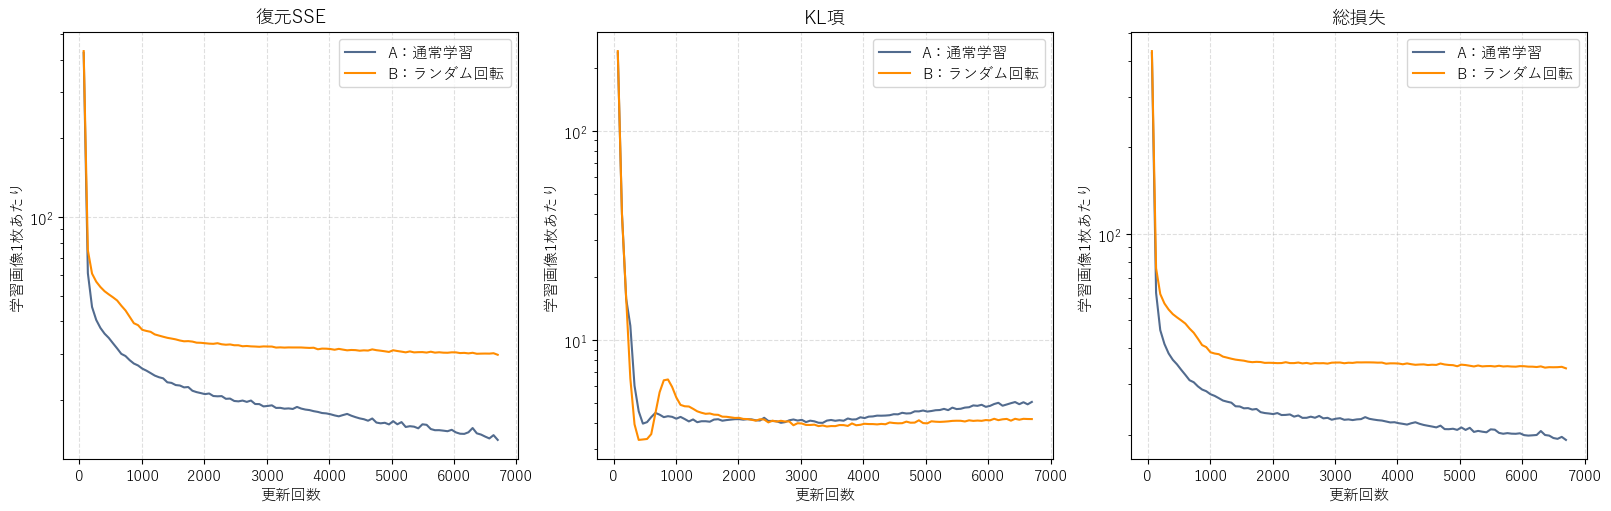

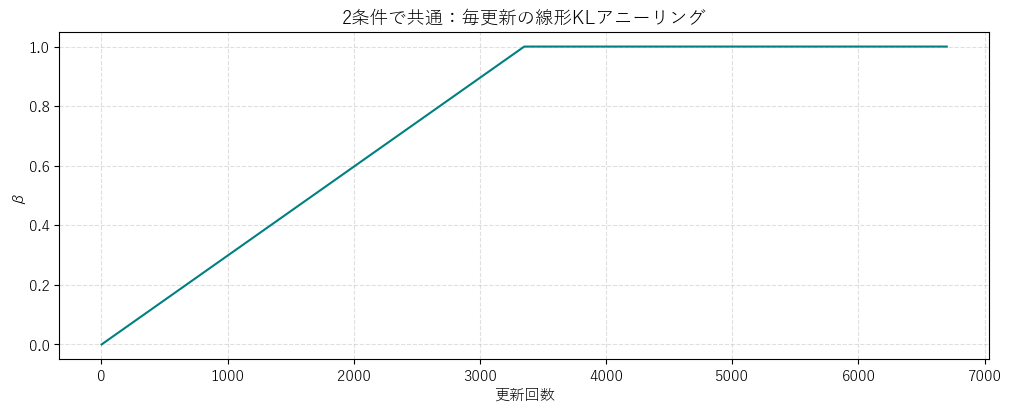

In [8]:
CURVE_DIR=RUN_DIR/'plots';CURVE_DIR.mkdir(exist_ok=True)
fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for condition in CONDITIONS:
    h=pd.read_csv(RUN_DIR/condition/'history.csv')
    for ax,key,title in zip(axes,['sse_per_image','kl_per_image','total_per_image'],['復元SSE','KL項','総損失']):
        ax.plot(h['update'],np.maximum(h[key],1e-12),label=LABELS[condition],color=COLORS[condition])
        ax.set(title=title,xlabel='更新回数',ylabel='学習画像1枚あたり',yscale='log');ax.grid(ls='--',alpha=.4);ax.legend()
fig.savefig(CURVE_DIR/'training_curves.png',dpi=180);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
ax.plot(np.arange(1,TARGET_UPDATES+1),beta_schedule,color='teal')
ax.set(title='2条件で共通：毎更新の線形KLアニーリング',xlabel='更新回数',ylabel='β');ax.grid(ls='--',alpha=.4)
fig.savefig(CURVE_DIR/'beta_schedule.png',dpi=180);plt.show();plt.close(fig)


## 4. 学習済みの最終重みで評価する

**主評価は回転なし83枚。** 補助評価は同じ83枚を1枚1角度で回転し、seed42〜46の5通りを比較する。
評価角度は1〜359度の整数から独立・等確率・重複ありで抽選。0度は含めない。
学習のランダム角度は連続値、評価の角度は1度単位であり、同一の角度表を学習に流用しない。
両モデルへ同じ入力を使用し、画像数・正常20／異常63の内訳は各回で変えない。

平均μで復元し、$1-\mathrm{SSIM}$マップ（窓11・data_range=1）の上位130点平均を画像スコアとする。
検出性能の指標はAUROCのみ。閾値探索や正常／異常の二値判定は追加しない。
正常20枚の復元MSE・SSIMは補助情報で、モデルの選択・学習には使わない。

合成回転の補完・切り取り・縮小の影響を含む。元の正常／異常ラベルを維持するが、
欠陥が切り取りで見えなくなっていないかは画像比較でも確認する。実撮影での向きの変化とは同一ではない。


In [9]:
EVAL_DIR=RUN_DIR/'evaluations'/new_id();EVAL_DIR.mkdir(parents=True,exist_ok=False)
INPUT_DIR=EVAL_DIR/'inputs';INPUT_DIR.mkdir()
CASES=[('unrotated',-1)]+[('random_rotated',seed) for seed in ASSIGNMENT_SEEDS]
assignment_rows=[];input_manifest=[]
for scenario,assignment_seed in CASES:
    if scenario=='unrotated':angles=np.zeros(len(test_images),dtype=int);inputs=test_base
    else:
        rng=np.random.default_rng(assignment_seed)
        angles=rng.choice(TEST_ANGLE_CANDIDATES,size=len(test_images),replace=True)
        inputs=torch.stack([to_tensor(final_transform(rotate_bottle(image,float(a))))
            for image,a in zip(test_images,angles)])
    assert inputs.shape==(83,1,128,128)
    np.savez_compressed(INPUT_DIR/f'{scenario}_seed{assignment_seed}.npz',inputs=inputs.numpy(),
        angles=angles,relative_paths=image_table.relative_path.to_numpy(dtype=str))
    for i,record in enumerate(test_manifest):
        assignment_rows.append({'scenario':scenario,'assignment_seed':assignment_seed,'relative_path':record['relative_path'],
            'category':record['category'],'true_label':record['true_label'],'angle':int(angles[i])})
        input_manifest.append({'scenario':scenario,'assignment_seed':assignment_seed,'relative_path':record['relative_path'],
            'angle':int(angles[i]),'source_sha256':record['file_sha256'],'preprocessed_sha256':tensor_hash(inputs[i])})
        if scenario=='unrotated':assert tensor_hash(inputs[i])==record['preprocessed_sha256']
assignments=pd.DataFrame(assignment_rows);assignments.to_csv(EVAL_DIR/'angle_assignments.csv',index=False)
write_json(EVAL_DIR/'input_manifest.json',input_manifest)
evaluation_config={'status':'prepared','created_at_jst':datetime.now(ZoneInfo('Asia/Tokyo')).isoformat(),
    'training_run':RUN_DIR.name,'contract_sha256':CONTRACT_SHA,'model_hashes':{k:summaries[k]['model_sha256'] for k in CONDITIONS},
    'train_manifest_sha256':object_hash(train_manifest),'test_manifest_sha256':object_hash(test_manifest),
    'metric':'AUROC','inference':'posterior mean','ssim_window':11,'data_range':1,'top_k':TOP_K,
    'test_angle_candidates':TEST_ANGLE_CANDIDATES.tolist(),'assignment_seeds':list(ASSIGNMENT_SEEDS),
    'angle_assignment':'independent numpy default_rng(seed).choice; 1 angle per image; no 0 degree',
    'representative_seed':REPRESENTATIVE_SEED,'versions':VERSIONS,'device':str(DEVICE),
    'training_versions':config['versions'],'training_device':config['device']}
write_json(EVAL_DIR/'config.json',evaluation_config)

models={};score_rows=[];auc_rows=[]
try:
    for condition in CONDITIONS:
        model=VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM).to(DEVICE)
        model.load_state_dict(torch.load(RUN_DIR/condition/'model_final.pth',map_location=DEVICE,weights_only=True),strict=True)
        model.eval();model.requires_grad_(False);models[condition]=model
    evaluation_config.update(status='running');write_json(EVAL_DIR/'config.json',evaluation_config)
    for scenario,assignment_seed in CASES:
        with np.load(INPUT_DIR/f'{scenario}_seed{assignment_seed}.npz',allow_pickle=False) as saved:
            assert saved['relative_paths'].tolist()==image_table.relative_path.tolist()
            inputs=torch.from_numpy(saved['inputs'].copy());angles=saved['angles'].copy()
        arrays={'relative_paths':image_table.relative_path.to_numpy(dtype=str),'angles':angles}
        for condition,model in models.items():
            scores,reconstructed,maps=score_loaded_model(model,inputs)
            mse,similarity=reconstruction_metrics(inputs,reconstructed)
            auc=verify_auroc(image_table.true_label.to_numpy(),scores)
            auc_rows.append({'condition':condition,'scenario':scenario,'assignment_seed':assignment_seed,'count':83,'auroc':auc})
            arrays[f'{condition}_reconstruction']=reconstructed;arrays[f'{condition}_error_map']=maps;arrays[f'{condition}_scores']=scores
            for i,row in image_table.iterrows():
                score_rows.append({'condition':condition,'scenario':scenario,'assignment_seed':assignment_seed,
                    'relative_path':row.relative_path,'category':row.category,'category_ja':row.category_ja,
                    'true_label':int(row.true_label),'angle':int(angles[i]),'score':float(scores[i]),'mse':float(mse[i]),'ssim':float(similarity[i])})
            print(f'{LABELS[condition]} / {SCENARIOS[scenario]} / seed{assignment_seed}：AUROC={auc:.4f}',flush=True)
        np.savez_compressed(EVAL_DIR/f'{scenario}_seed{assignment_seed}.npz',**arrays)
        pd.DataFrame(score_rows).to_csv(EVAL_DIR/'image_scores.csv',index=False)
        pd.DataFrame(auc_rows).to_csv(EVAL_DIR/'trial_auroc.csv',index=False)
    evaluation_config.update(status='inference_completed');write_json(EVAL_DIR/'config.json',evaluation_config)
except BaseException as exc:
    evaluation_config.update(status='failed_or_interrupted',error=f'{type(exc).__name__}: {exc}')
    write_json(EVAL_DIR/'config.json',evaluation_config);raise
finally:
    models.clear()
    if 'model' in globals():del model
scores_table=pd.DataFrame(score_rows);trial_auroc=pd.DataFrame(auc_rows)
assert len(scores_table)==len(test_images)*len(CASES)*len(CONDITIONS) and len(trial_auroc)==len(CASES)*len(CONDITIONS)
assert not scores_table.duplicated(['condition','scenario','assignment_seed','relative_path']).any()
print('評価保存先：',EVAL_DIR)


A：通常学習 / 回転なし（主評価） / seed-1：AUROC=0.9730
B：ランダム回転 / 回転なし（主評価） / seed-1：AUROC=0.9611
A：通常学習 / ランダム回転（補助評価） / seed42：AUROC=0.8270
B：ランダム回転 / ランダム回転（補助評価） / seed42：AUROC=0.9619
A：通常学習 / ランダム回転（補助評価） / seed43：AUROC=0.8333
B：ランダム回転 / ランダム回転（補助評価） / seed43：AUROC=0.9667
A：通常学習 / ランダム回転（補助評価） / seed44：AUROC=0.8889
B：ランダム回転 / ランダム回転（補助評価） / seed44：AUROC=0.9571
A：通常学習 / ランダム回転（補助評価） / seed45：AUROC=0.8762
B：ランダム回転 / ランダム回転（補助評価） / seed45：AUROC=0.9548
A：通常学習 / ランダム回転（補助評価） / seed46：AUROC=0.7857
B：ランダム回転 / ランダム回転（補助評価） / seed46：AUROC=0.9627
評価保存先： c:\Users\tokiy\my_GitHub\image-anomaly-detection\saved_models\bottle_random_rotation_20261119\20261119_205058_0774e375\evaluations\20261119_225058_0d693a58


## 5. AUROC・正常画像の復元品質・種類別の集計

元の83枚でのAUROCを主結果として確認する。ランダム回転の5回は各83枚のAUROCを平均する。
5回分を独立した415枚としてプールしない。ばらつきは角度割り当てによるもので、学習シード間の変動ではない。
モデル差は同じ角度割り当てのB−A。標準偏差は標本標準偏差（ddof=1）で、単一回の値には付けない。


In [10]:
auc_summary=trial_auroc.groupby(['scenario','condition'],sort=False).agg(
    auroc_mean=('auroc','mean'),auroc_std=('auroc','std'),assignment_count=('auroc','size')).reset_index()
auc_summary.to_csv(EVAL_DIR/'auroc_summary.csv',index=False)
display(auc_summary.replace({'scenario':SCENARIOS,'condition':LABELS}))
paired=trial_auroc.pivot(index=['scenario','assignment_seed'],columns='condition',values='auroc')
paired['B_minus_A']=paired['B_random']-paired['A_normal']
paired.to_csv(EVAL_DIR/'paired_differences.csv');display(paired.rename(columns=LABELS))
paired_summary=paired.groupby('scenario',sort=False).agg(mean_B_minus_A=('B_minus_A','mean'),
    std_B_minus_A=('B_minus_A','std'),assignment_count=('B_minus_A','size')).reset_index()
paired_summary.to_csv(EVAL_DIR/'paired_difference_summary.csv',index=False)
normal_trials=scores_table[scores_table.category=='good'].groupby(['scenario','assignment_seed','condition'],sort=False).agg(
    mse=('mse','mean'),ssim=('ssim','mean'),mean_score=('score','mean'),count=('score','size')).reset_index()
assert (normal_trials['count']==20).all()
normal_summary=normal_trials.groupby(['scenario','condition'],sort=False).agg(
    mse_mean=('mse','mean'),mse_std=('mse','std'),ssim_mean=('ssim','mean'),ssim_std=('ssim','std')).reset_index()
normal_trials.to_csv(EVAL_DIR/'normal_reconstruction_by_trial.csv',index=False)
normal_summary.to_csv(EVAL_DIR/'normal_reconstruction_summary.csv',index=False)
display(normal_summary.replace({'scenario':SCENARIOS,'condition':LABELS}))
category_rows=[]
for (scenario,assignment_seed,condition),part in scores_table.groupby(['scenario','assignment_seed','condition'],sort=False):
    for category in CATEGORY_LABELS:
        if category=='good':continue
        selected=part[part.category.isin(['good',category])]
        assert len(selected)==20+counts[category]
        category_rows.append({'scenario':scenario,'assignment_seed':assignment_seed,'condition':condition,'category':category,
            'category_ja':CATEGORY_LABELS[category],'normal_count':20,'abnormal_count':counts[category],
            'auroc':verify_auroc(selected.true_label.to_numpy(),selected.score.to_numpy())})
category_trials=pd.DataFrame(category_rows)
category_summary=category_trials.groupby(['scenario','condition','category_ja'],sort=False).agg(
    auroc_mean=('auroc','mean'),auroc_std=('auroc','std'),assignment_count=('auroc','size')).reset_index()
category_trials.to_csv(EVAL_DIR/'category_trial_auroc.csv',index=False)
category_summary.to_csv(EVAL_DIR/'category_auroc_summary.csv',index=False)
display(category_summary.replace({'scenario':SCENARIOS,'condition':LABELS}))


,scenario,condition,auroc_mean,auroc_std,assignment_count
0,回転なし（主評価）,A：通常学習,0.973016,NaN,1
1,回転なし（主評価）,B：ランダム回転,0.961111,NaN,1
2,ランダム回転（補助評価）,A：通常学習,0.842222,0.041340,5
3,ランダム回転（補助評価）,B：ランダム回転,0.960635,0.004715,5


condition                         A：通常学習  B：ランダム回転  B_minus_A
scenario       assignment_seed                               
random_rotated  42              0.826984  0.961905   0.134921
                43              0.833333  0.966667   0.133333
                44              0.888889  0.957143   0.068254
                45              0.876190  0.954762   0.078571
                46              0.785714  0.962698   0.176984
unrotated      -1               0.973016  0.961111  -0.011905

,scenario,condition,mse_mean,mse_std,ssim_mean,ssim_std
0,回転なし（主評価）,A：通常学習,0.001901,NaN,0.867486,NaN
1,回転なし（主評価）,B：ランダム回転,0.002088,NaN,0.846567,NaN
2,ランダム回転（補助評価）,A：通常学習,0.003685,0.000139,0.795874,0.010556
3,ランダム回転（補助評価）,B：ランダム回転,0.002079,0.000015,0.846807,0.000410


,scenario,condition,category_ja,auroc_mean,auroc_std,assignment_count
0,回転なし（主評価）,A：通常学習,大きな破損,1.000000,NaN,1
1,回転なし（主評価）,A：通常学習,小さな破損,0.988636,NaN,1
2,回転なし（主評価）,A：通常学習,汚れ・異物,0.930952,NaN,1
3,回転なし（主評価）,B：ランダム回転,大きな破損,1.000000,NaN,1
4,回転なし（主評価）,B：ランダム回転,小さな破損,0.975000,NaN,1
5,回転なし（主評価）,B：ランダム回転,汚れ・異物,0.909524,NaN,1
6,ランダム回転（補助評価）,A：通常学習,大きな破損,0.923000,0.030639,5
7,ランダム回転（補助評価）,A：通常学習,小さな破損,0.825455,0.036906,5
8,ランダム回転（補助評価）,A：通常学習,汚れ・異物,0.782857,0.062120,5
9,ランダム回転（補助評価）,B：ランダム回転,大きな破損,1.000000,0.000000,5


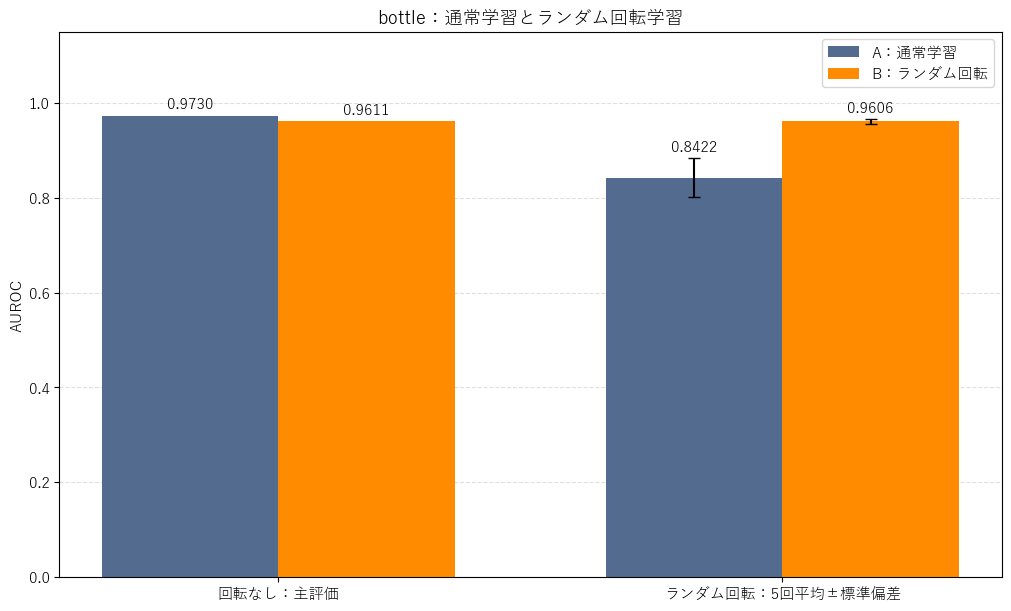

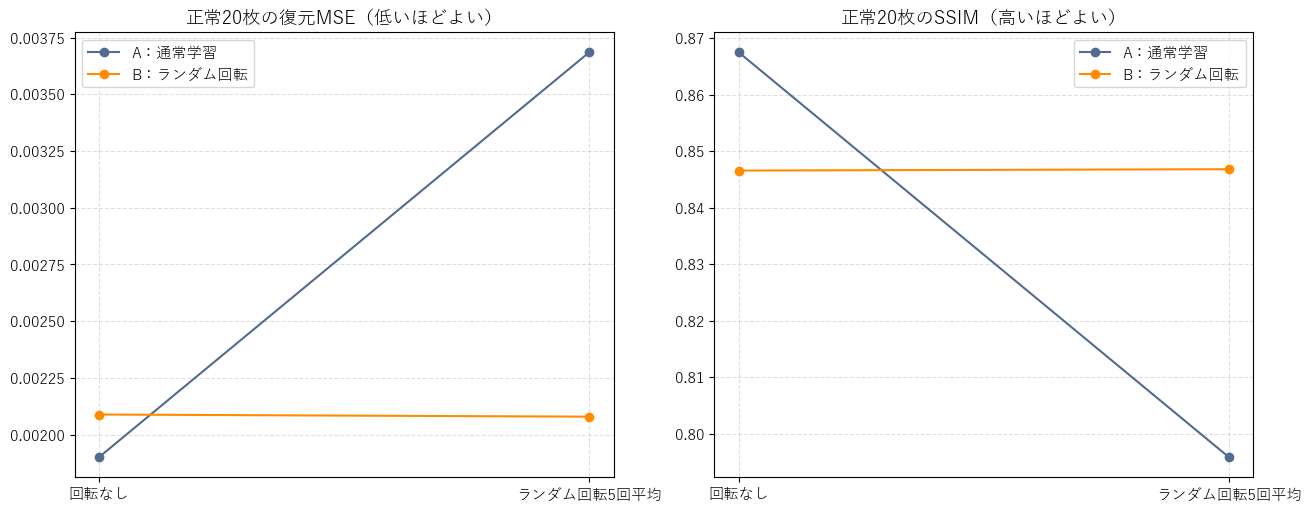

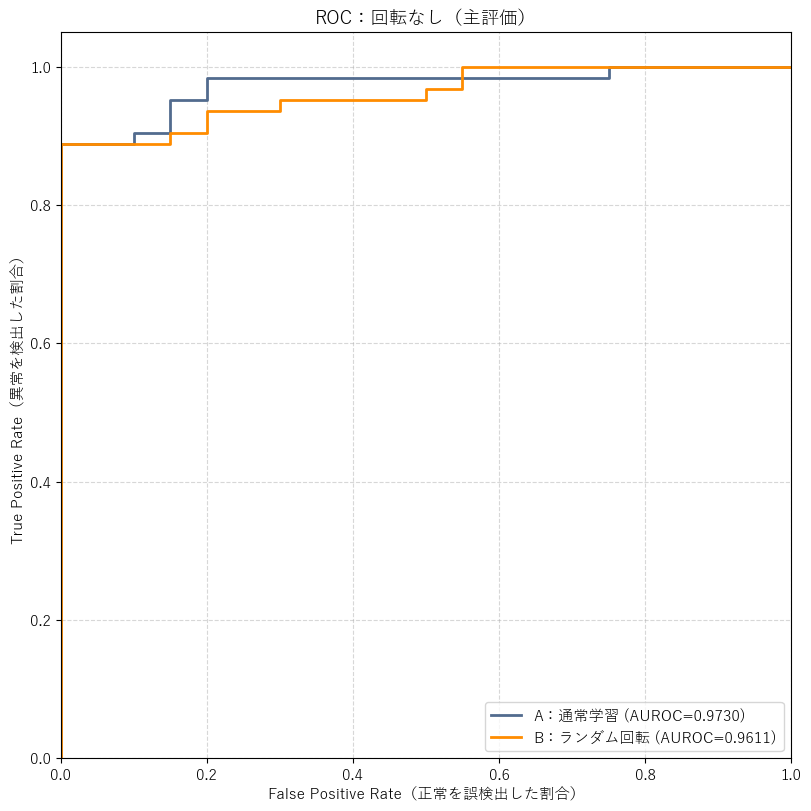

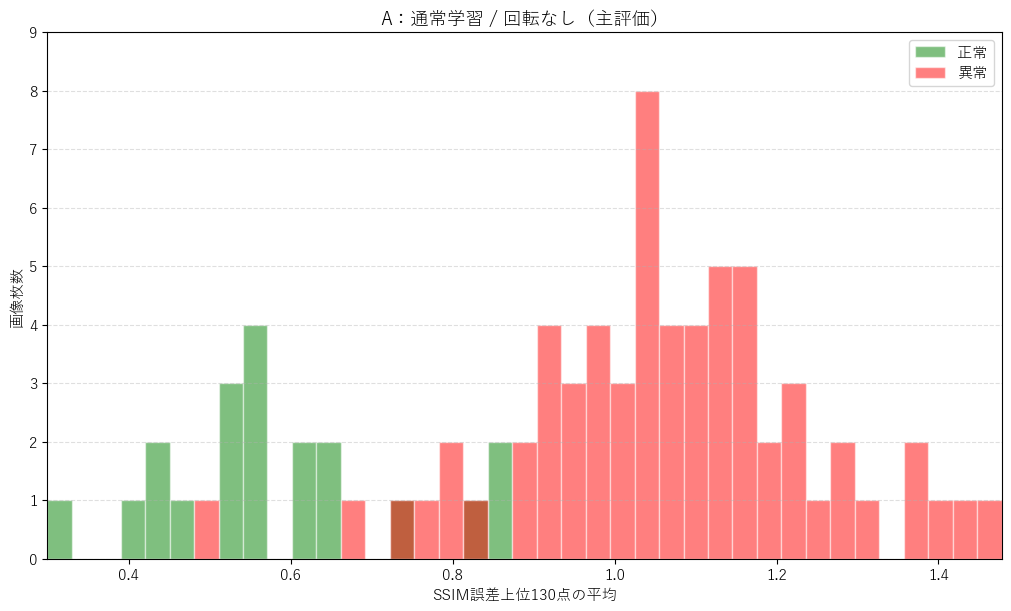

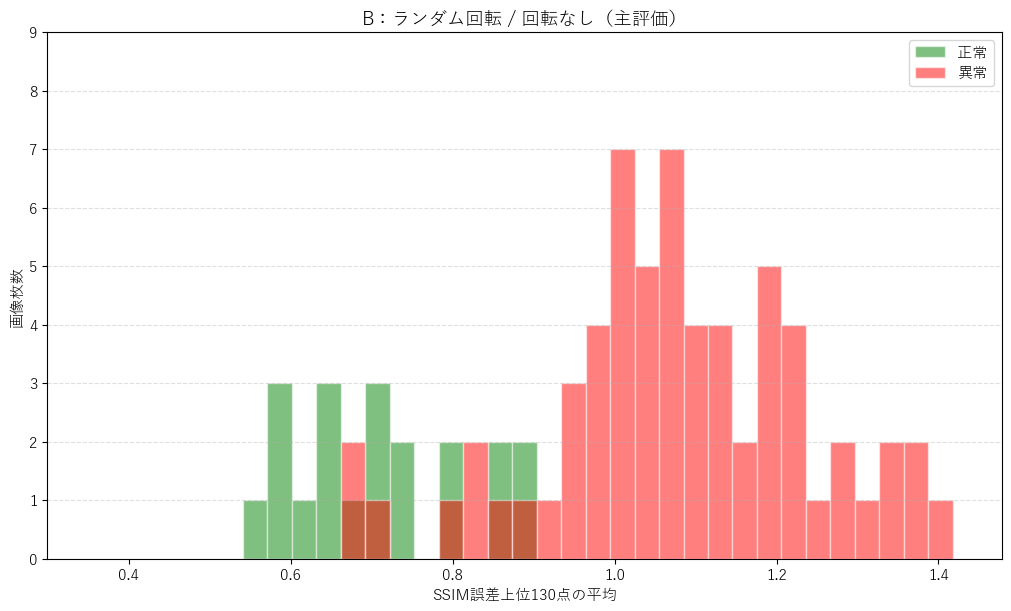

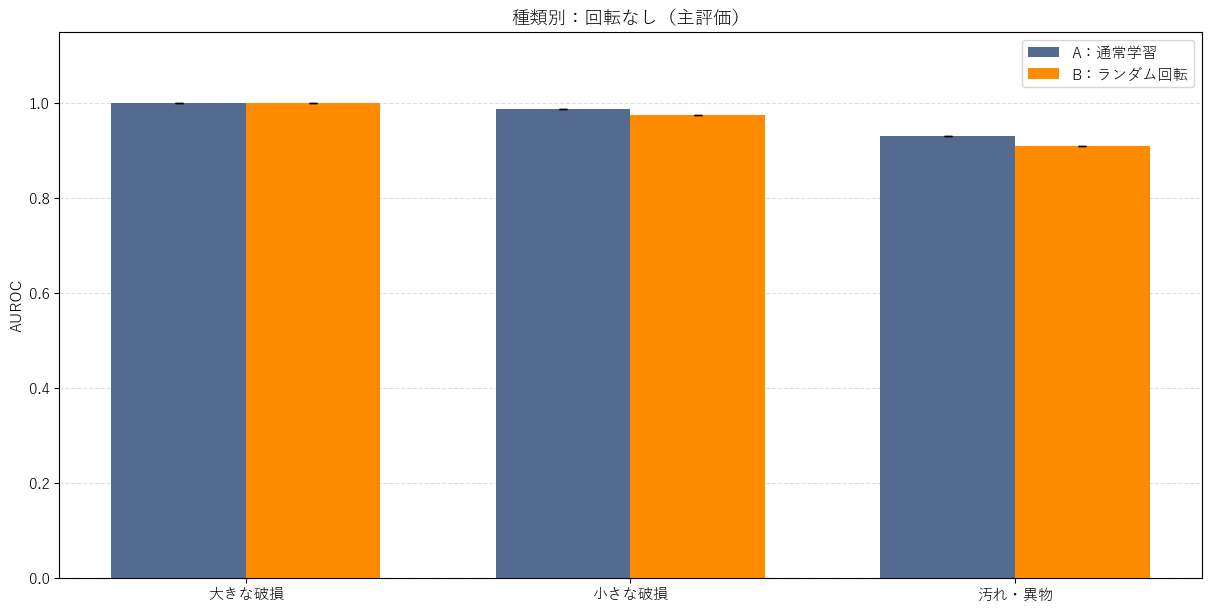

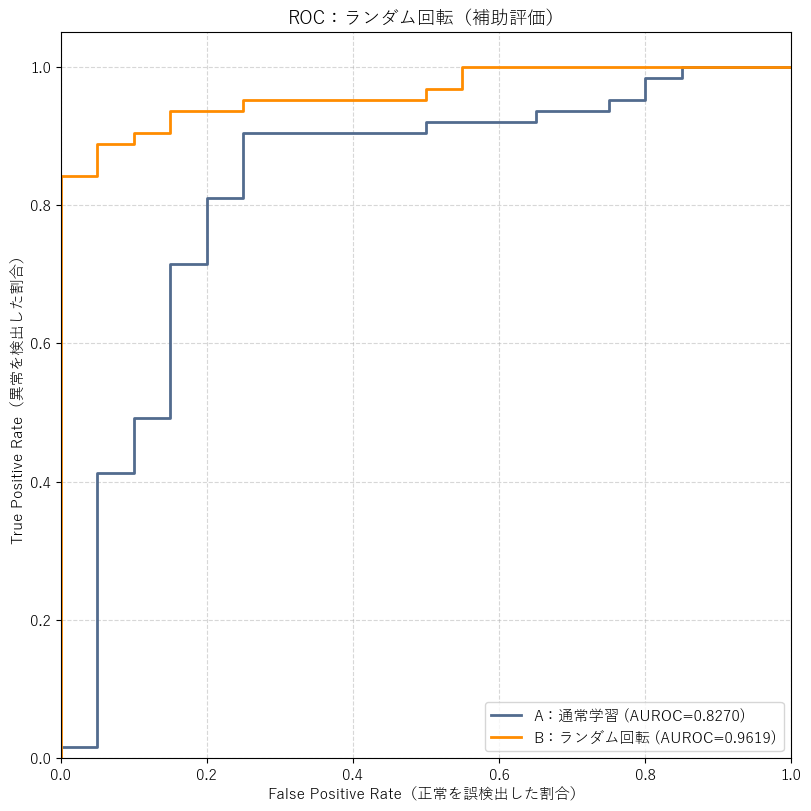

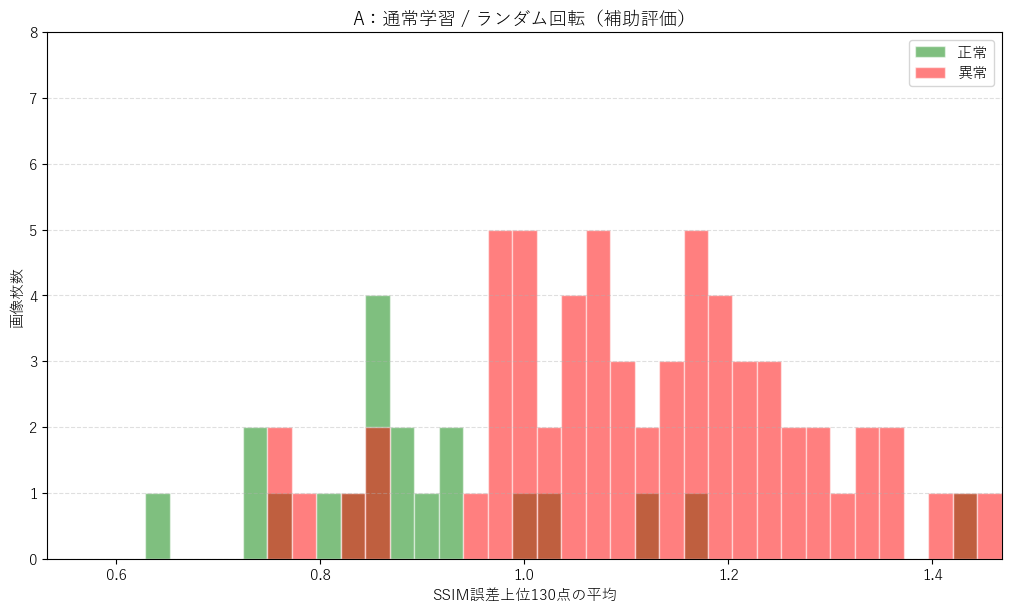

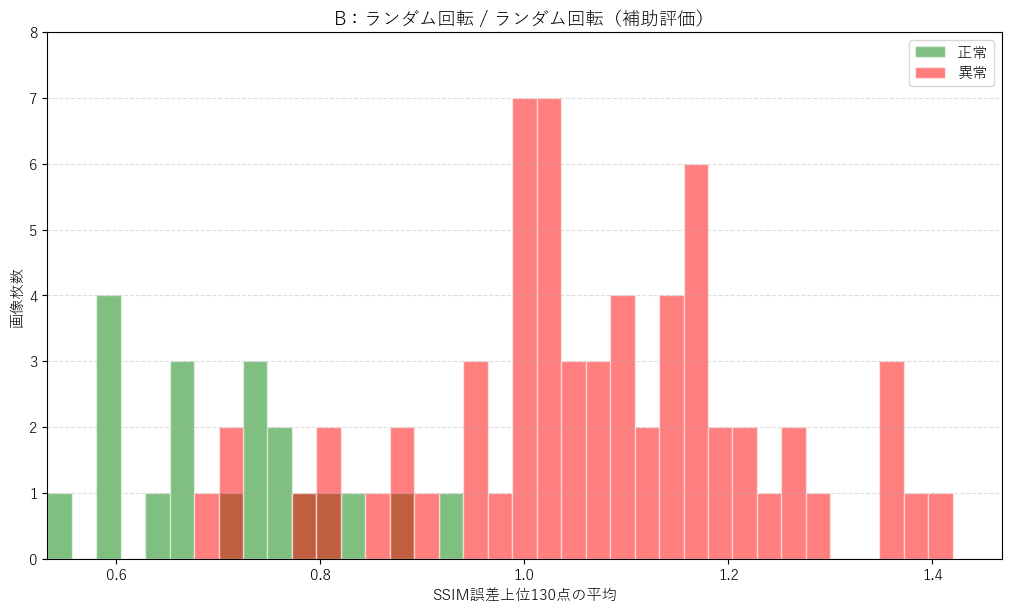

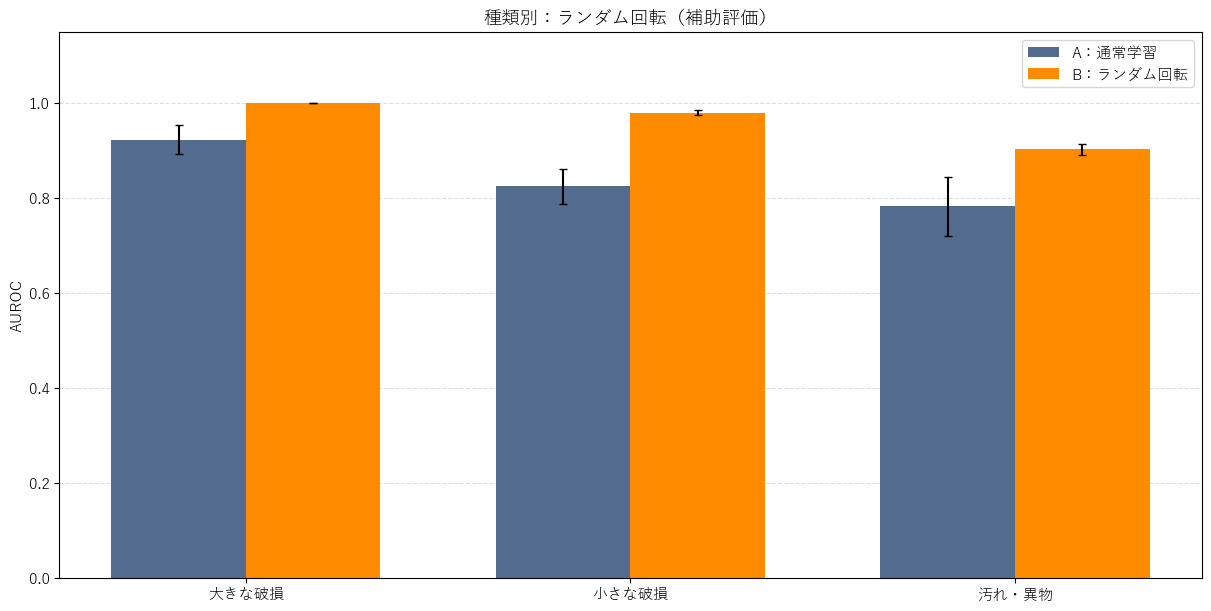

In [11]:
fig,ax=plt.subplots(figsize=(10,6),constrained_layout=True);x=np.arange(2);width=.35
for offset,condition in enumerate(CONDITIONS):
    part=auc_summary[auc_summary.condition==condition].set_index('scenario').loc[list(SCENARIOS)]
    positions=x+(offset-.5)*width
    ax.bar(positions,part.auroc_mean,width,color=COLORS[condition],label=LABELS[condition])
    std=part.auroc_std;mask=std.notna().to_numpy()
    ax.errorbar(positions[mask],part.auroc_mean.to_numpy()[mask],yerr=std.to_numpy()[mask],fmt='none',ecolor='black',capsize=4)
    for pos,value,error in zip(positions,part.auroc_mean,std.fillna(0)):ax.text(pos,value+error+.015,f'{value:.4f}',ha='center')
ax.set(xticks=x,xticklabels=['回転なし：主評価','ランダム回転：5回平均±標準偏差'],ylim=(0,1.15),ylabel='AUROC',title='bottle：通常学習とランダム回転学習')
ax.legend();ax.grid(axis='y',ls='--',alpha=.4);ax.set_axisbelow(True)
fig.savefig(EVAL_DIR/'auroc_comparison.png',dpi=180);plt.show();plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,key,title in zip(axes,['mse_mean','ssim_mean'],['正常20枚の復元MSE（低いほどよい）','正常20枚のSSIM（高いほどよい）']):
    for condition in CONDITIONS:
        part=normal_summary[normal_summary.condition==condition].set_index('scenario').loc[list(SCENARIOS)]
        ax.plot(x,part[key],'o-',color=COLORS[condition],label=LABELS[condition])
    ax.set(xticks=x,xticklabels=['回転なし','ランダム回転5回平均'],title=title)
    ax.legend();ax.grid(ls='--',alpha=.4)
fig.savefig(EVAL_DIR/'normal_reconstruction.png',dpi=180);plt.show();plt.close(fig)

for scenario in SCENARIOS:
    representative=-1 if scenario=='unrotated' else REPRESENTATIVE_SEED
    selected=scores_table[(scores_table.scenario==scenario)&(scores_table.assignment_seed==representative)]
    fig,ax=plt.subplots(figsize=(8,8),constrained_layout=True)
    for condition in CONDITIONS:
        part=selected[selected.condition==condition]
        fpr,tpr,_=binary_roc_curve(part.true_label.to_numpy(),part.score.to_numpy())
        auc=verify_auroc(part.true_label.to_numpy(),part.score.to_numpy())
        ax.plot(fpr,tpr,color=COLORS[condition],lw=2,label=f'{LABELS[condition]} (AUROC={auc:.4f})')
    ax.set(xlim=(0,1),ylim=(0,1.05),xlabel='False Positive Rate（正常を誤検出した割合）',
        ylabel='True Positive Rate（異常を検出した割合）',title='ROC：'+SCENARIOS[scenario])
    ax.legend(loc='lower right');ax.grid(ls='--',alpha=.5)
    fig.savefig(EVAL_DIR/f'roc_{scenario}.png',dpi=180);plt.show();plt.close(fig)
    lo,hi=float(selected.score.min()),float(selected.score.max())
    if lo==hi:lo-=1e-6;hi+=1e-6
    bins=np.linspace(lo,hi,40)
    ymax=max(np.histogram(selected.loc[(selected.condition==c)&(selected.true_label==label),'score'],bins=bins)[0].max()
        for c in CONDITIONS for label in [0,1])+1
    for condition in CONDITIONS:
        part=selected[selected.condition==condition];fig,ax=plt.subplots(figsize=(10,6),constrained_layout=True)
        for label,color,text in [(0,'green','正常'),(1,'red','異常')]:
            ax.hist(part.loc[part.true_label==label,'score'],bins=bins,color=color,alpha=.5,edgecolor='white',label=text)
        ax.set(xlim=(lo,hi),ylim=(0,ymax),xlabel='SSIM誤差上位130点の平均',ylabel='画像枚数',title=f'{LABELS[condition]} / {SCENARIOS[scenario]}')
        ax.legend();ax.grid(axis='y',ls='--',alpha=.4)
        fig.savefig(EVAL_DIR/f'hist_{scenario}_{condition}.png',dpi=180);plt.show();plt.close(fig)
    categories=[CATEGORY_LABELS[c] for c in CATEGORY_LABELS if c!='good'];fig,ax=plt.subplots(figsize=(12,6),constrained_layout=True)
    for offset,condition in enumerate(CONDITIONS):
        part=category_summary[(category_summary.scenario==scenario)&(category_summary.condition==condition)].set_index('category_ja').loc[categories]
        ax.bar(np.arange(3)+(offset-.5)*width,part.auroc_mean,width,yerr=part.auroc_std.fillna(0),capsize=3,color=COLORS[condition],label=LABELS[condition])
    ax.set(xticks=np.arange(3),xticklabels=categories,ylim=(0,1.15),ylabel='AUROC',title='種類別：'+SCENARIOS[scenario])
    ax.legend();ax.grid(axis='y',ls='--',alpha=.4);ax.set_axisbelow(True)
    fig.savefig(EVAL_DIR/f'category_{scenario}.png',dpi=180);plt.show();plt.close(fig)


## 6. 入力・復元・誤差マップを写真で比較

初期表示は正常・各異常の先頭1画像、回転なしとランダム回転seed42。
設定の `MAX_IMAGES_PER_CATEGORY=None` で全83枚、`VISUAL_PATHS` で指定画像を表示できる。
他の割り当てを見る場合は `VISUAL_CASES` に `('random_rotated',43)` などを指定する。
設定値は表示セルの直前で変更できる。表示だけなら推論はやり直さない。

誤差マップは全画像・全条件で0〜2の同じ色範囲。欠陥の正解位置ではなく入力と復元の違い。
回転前後で欠陥が見えているか、正常画像でも向き・細部・背景に大きな誤差が出るかを確認する。
角度推定や推定角度の数値は追加しない。


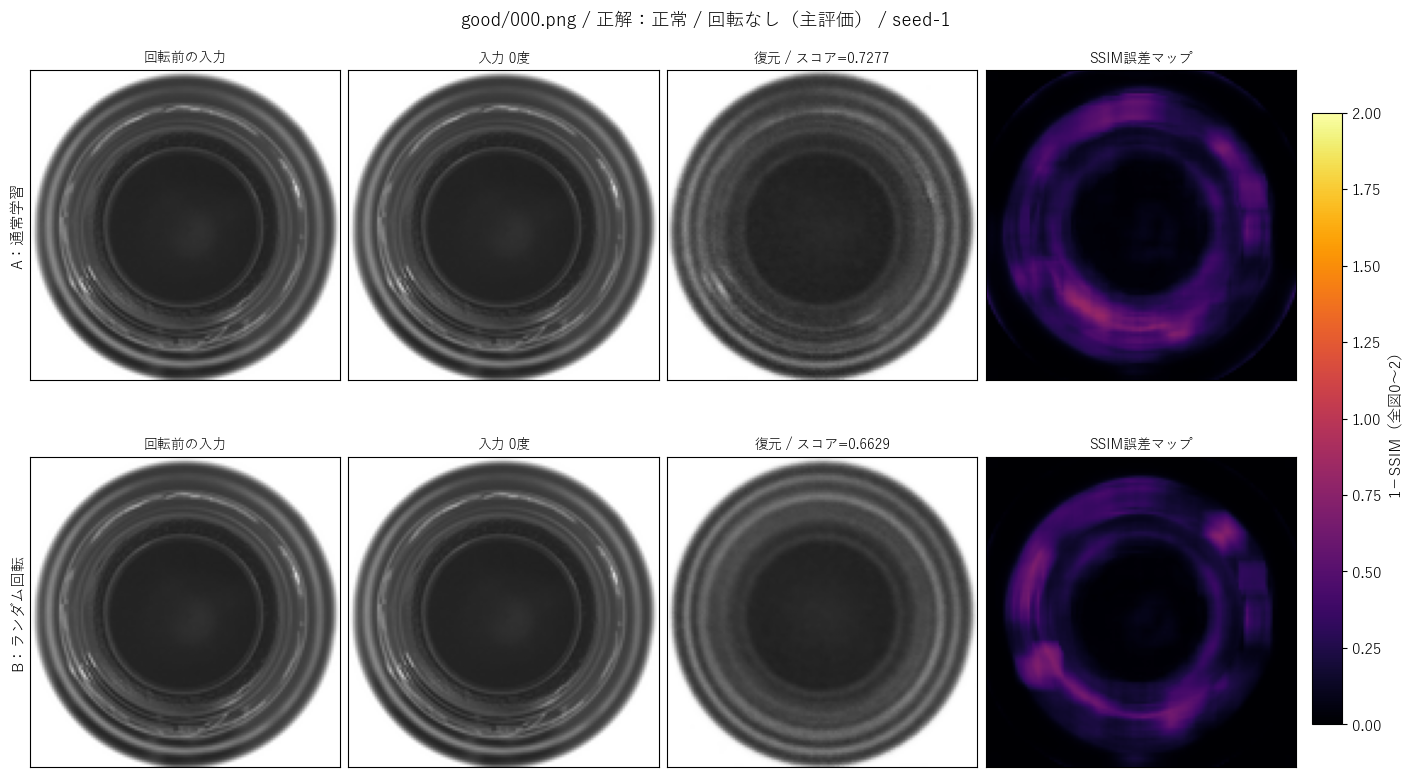

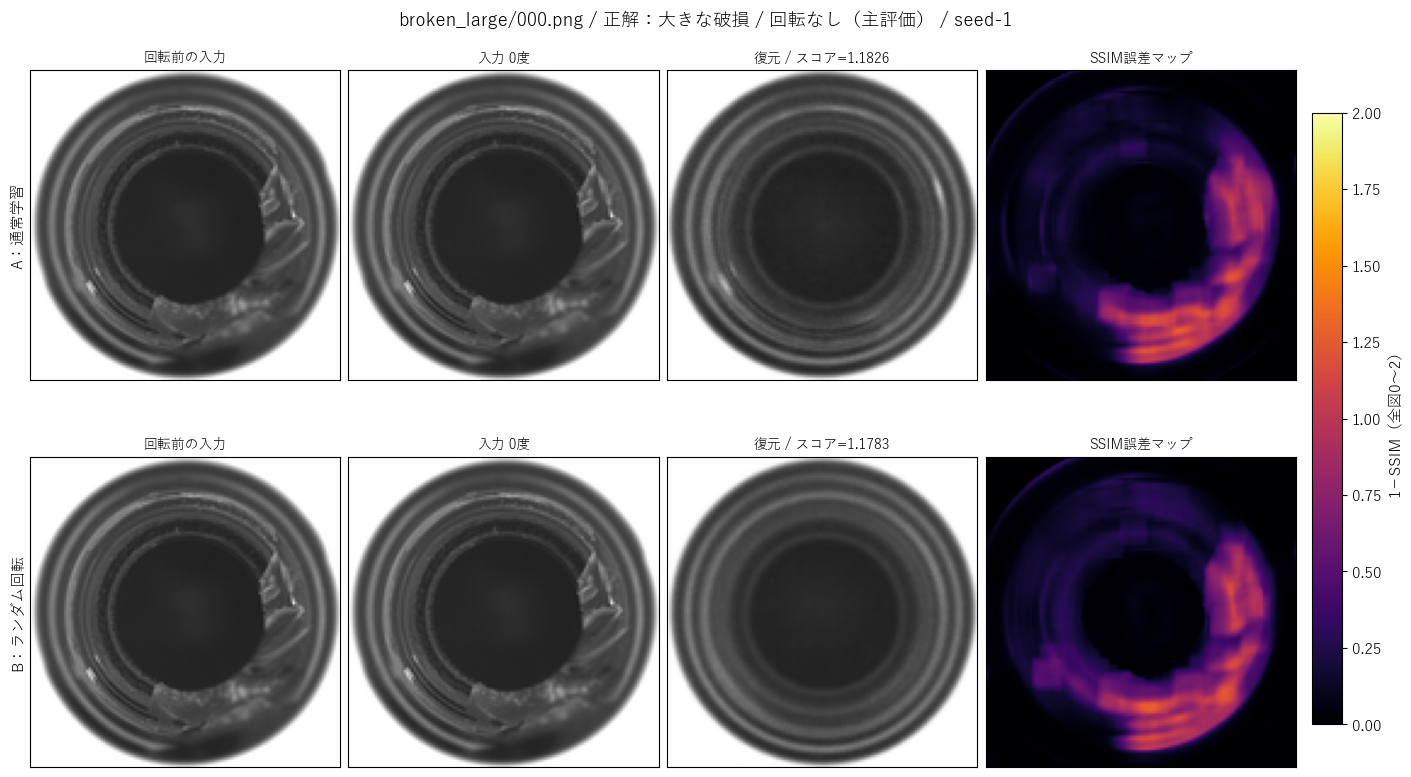

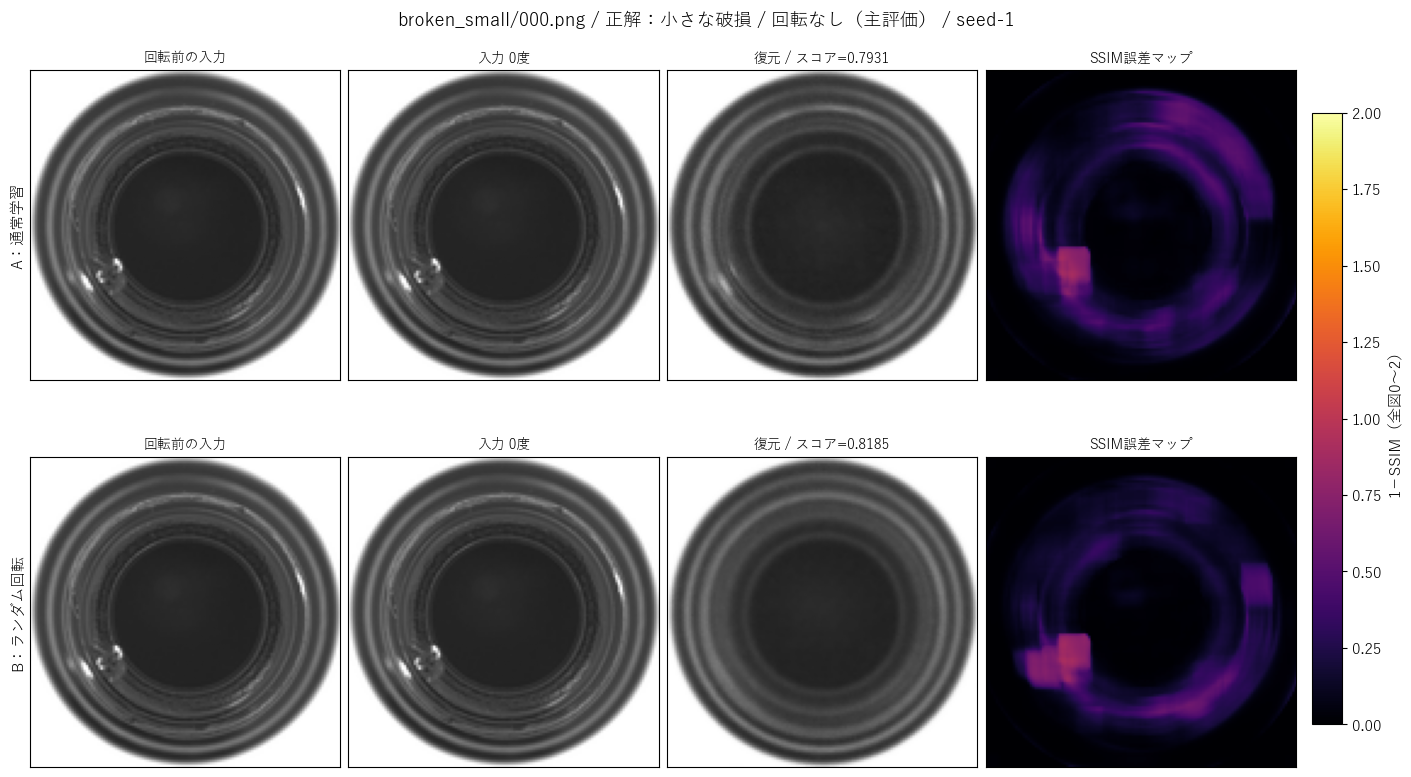

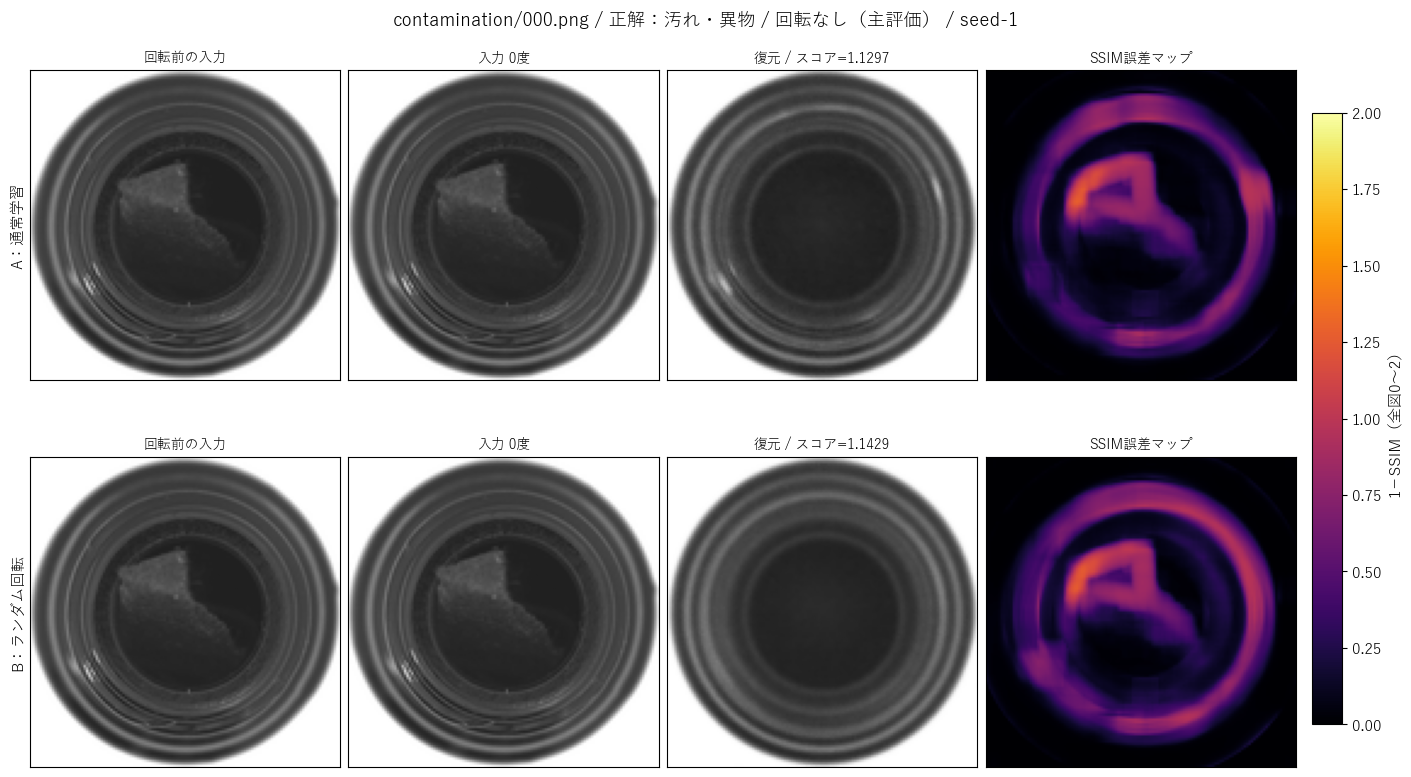

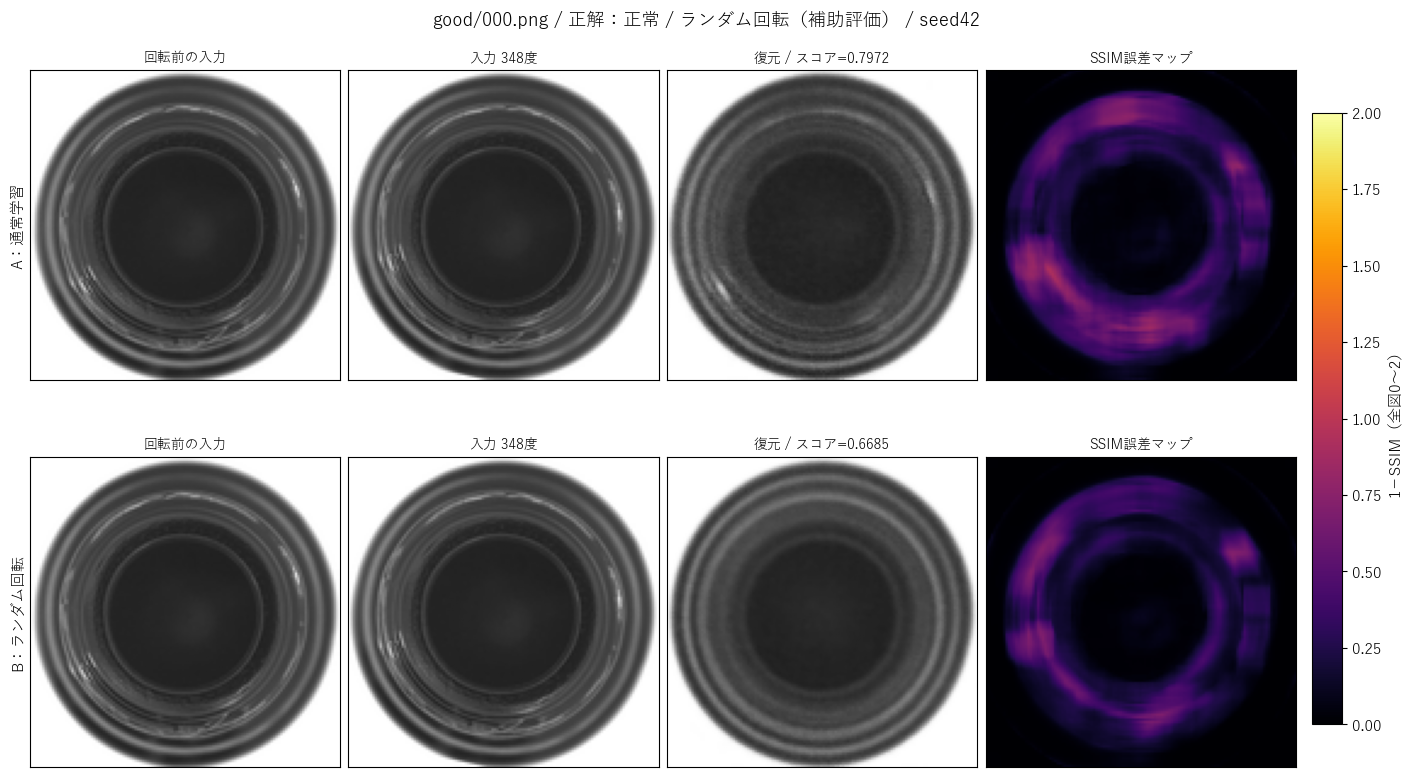

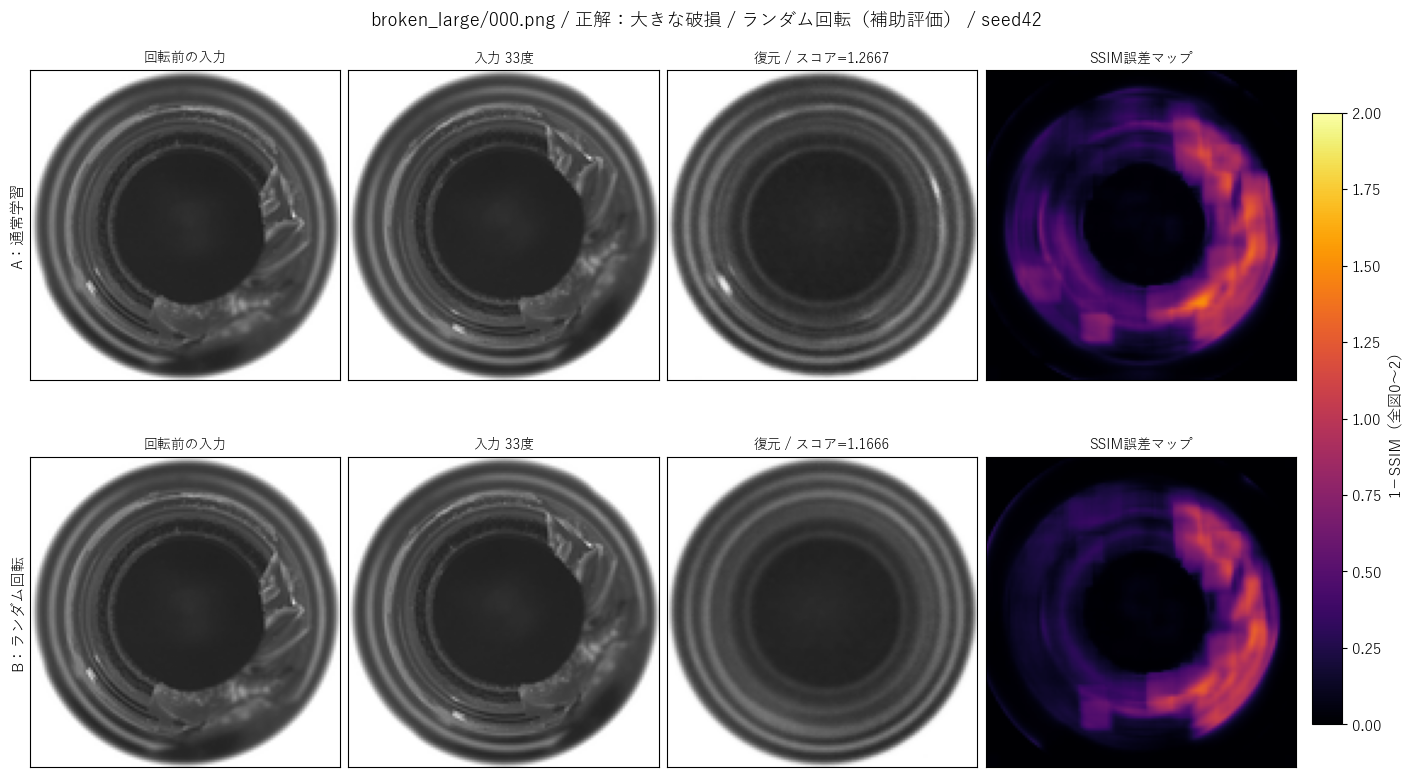

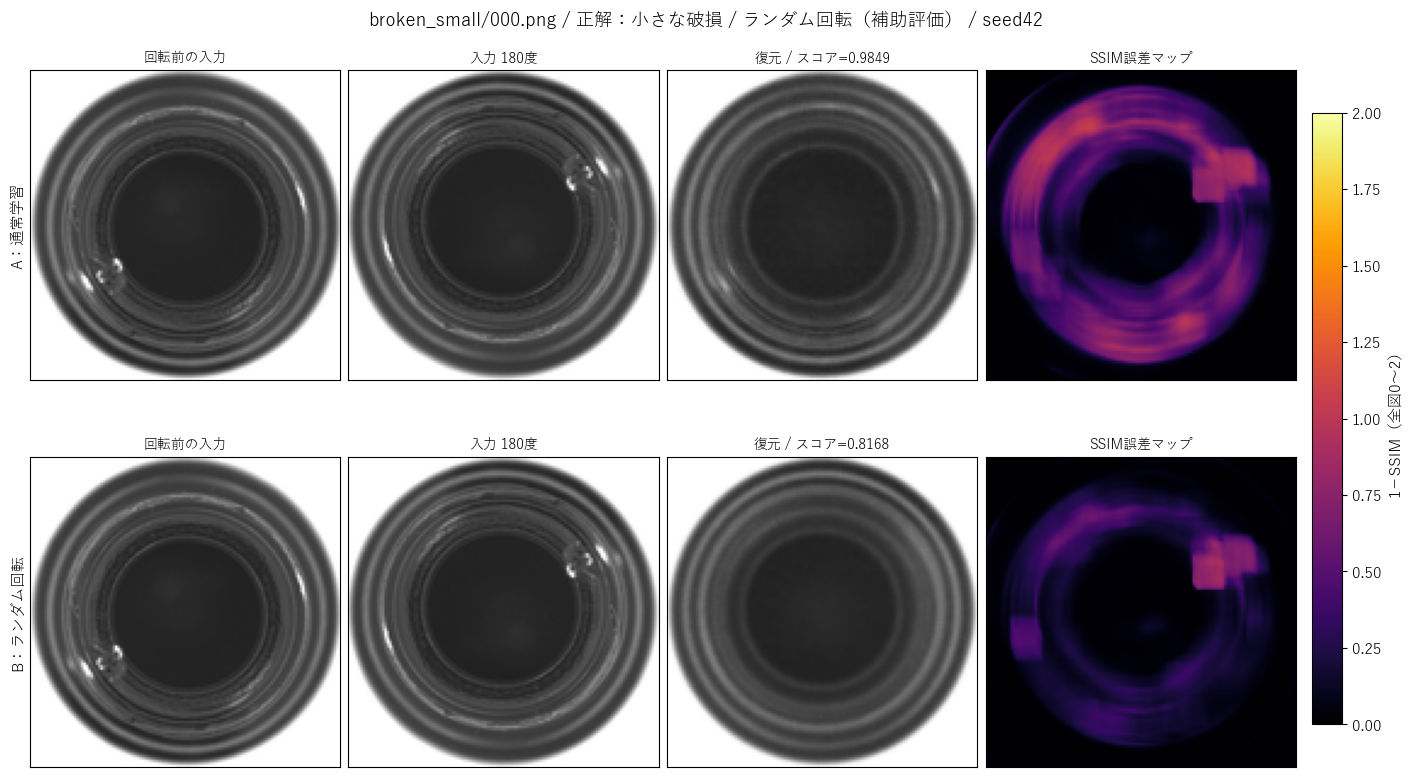

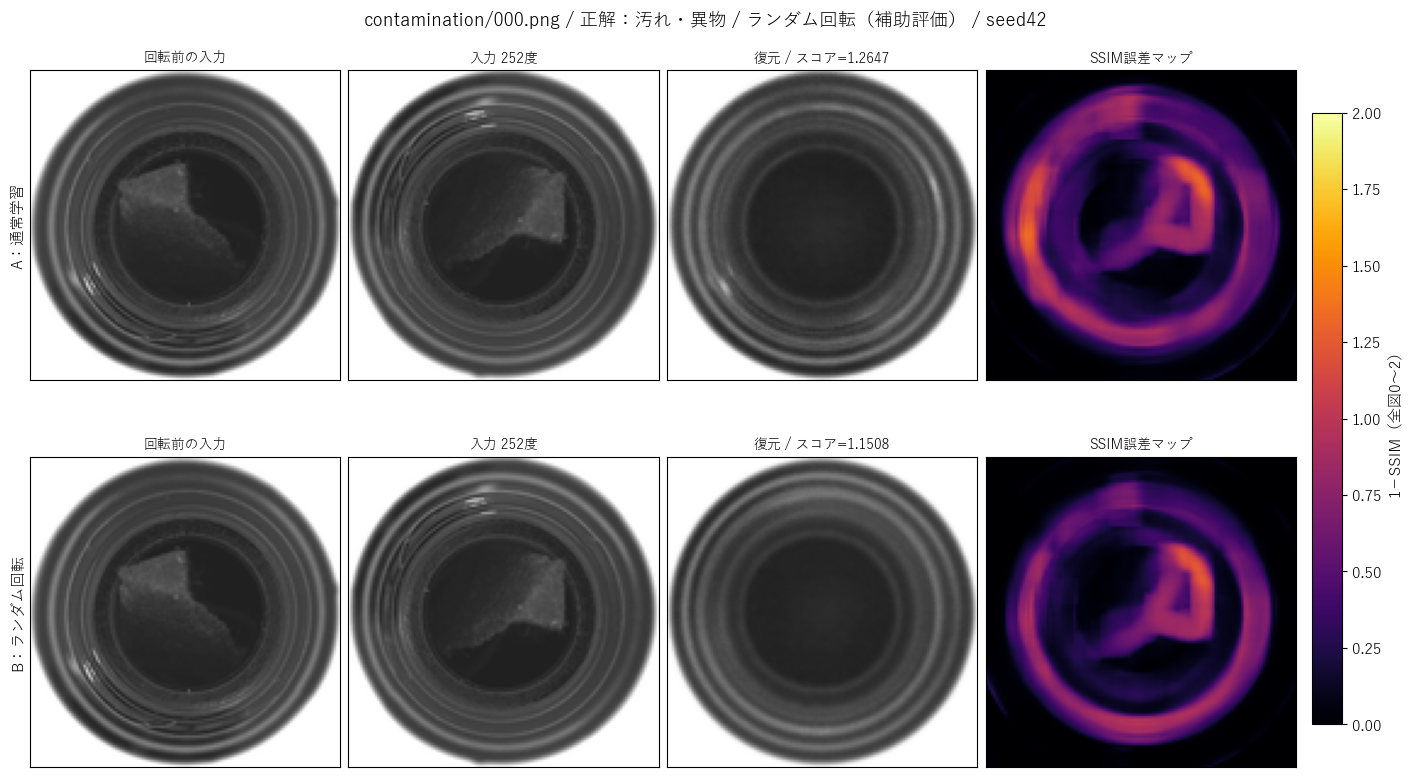

In [12]:
if VISUAL_PATHS is not None:
    assert set(VISUAL_PATHS).issubset(set(image_table.relative_path))
    visual_indices=image_table.index[image_table.relative_path.isin(VISUAL_PATHS)].tolist()
else:
    assert MAX_IMAGES_PER_CATEGORY is None or (isinstance(MAX_IMAGES_PER_CATEGORY,int) and not isinstance(MAX_IMAGES_PER_CATEGORY,bool) and MAX_IMAGES_PER_CATEGORY>0)
    visual_indices=[]
    for category in CATEGORY_LABELS:
        indices=image_table.index[image_table.category==category].tolist()
        visual_indices.extend(indices if MAX_IMAGES_PER_CATEGORY is None else indices[:MAX_IMAGES_PER_CATEGORY])
visual_dir=EVAL_DIR/'visualizations';visual_dir.mkdir(exist_ok=True)
for scenario,assignment_seed in VISUAL_CASES:
    assert (scenario,assignment_seed) in CASES
    with np.load(INPUT_DIR/f'{scenario}_seed{assignment_seed}.npz',allow_pickle=False) as saved:
        inputs=saved['inputs'].copy();angles=saved['angles'].copy()
        assert saved['relative_paths'].tolist()==image_table.relative_path.tolist()
    with np.load(EVAL_DIR/f'{scenario}_seed{assignment_seed}.npz',allow_pickle=False) as saved:
        arrays={k:saved[k] for k in saved.files}
    assert arrays['relative_paths'].tolist()==image_table.relative_path.tolist() and np.array_equal(arrays['angles'],angles)
    for index in visual_indices:
        row=image_table.loc[index];fig,axes=plt.subplots(2,4,figsize=(14,8),constrained_layout=True)
        for r,condition in enumerate(CONDITIONS):
            axes[r,0].imshow(test_base[index,0],cmap='gray',vmin=0,vmax=1)
            axes[r,1].imshow(inputs[index,0],cmap='gray',vmin=0,vmax=1)
            axes[r,2].imshow(arrays[f'{condition}_reconstruction'][index],cmap='gray',vmin=0,vmax=1)
            heat=axes[r,3].imshow(arrays[f'{condition}_error_map'][index],cmap='inferno',vmin=0,vmax=2)
            axes[r,0].set_ylabel(LABELS[condition])
            for col,title in enumerate(['回転前の入力',f'入力 {angles[index]:g}度',f'復元 / スコア={arrays[f"{condition}_scores"][index]:.4f}','SSIM誤差マップ']):
                axes[r,col].set_title(title,fontsize=10);axes[r,col].set_xticks([]);axes[r,col].set_yticks([])
        fig.colorbar(heat,ax=axes[:,3],label='1−SSIM（全図0〜2）',shrink=.8)
        fig.suptitle(f'{row.relative_path} / 正解：{row.category_ja} / {SCENARIOS[scenario]} / seed{assignment_seed}')
        stem=row.relative_path.replace('/','_').replace('.png','')
        fig.savefig(visual_dir/f'{scenario}_seed{assignment_seed}_{stem}.png',dpi=150);plt.show();plt.close(fig)


## 7. 考察の順序・完了記録

1. 元のbottle画像のAUROCが改善したかを主評価とする。
2. 回転した検査画像だけで改善した場合は、主に向きの変動への対応と解釈する。
3. 正常の復元MSE・SSIM・写真を確認する。復元が鮮明になることと異常検知が良くなることは同一ではない。
4. 正常・異常のスコア分布と種類別AUROCを比較し、全体値だけで結論しない。

「円形だから回転は無意味」「ランダム回転なら必ず有効」「回転すると必ずぼける」とは前提にしない。
円形の外形でも、内部模様・汚れ・破損・撮影条件の向きは変わり得るため、結果で判断する。
既存のHybrid以外の結果との差を回転だけの効果とは解釈しない。
1つの学習seed・同じ83枚での繰り返しであり、実環境の性能や一般的な優位性は保証されない。

評価のCSV・入出力配列・図は `evaluations/新規ID/` へ保存する。
完了済み重みを再利用する場合も、評価は新規IDに保存し、既存評価は上書きしない。


In [13]:
assert all(sha256(ROOT/r['repo_path'])==r['file_sha256'] for r in train_manifest+test_manifest),'元画像が変更されています。'
assert all(sha256(RUN_DIR/k/'model_final.pth')==summaries[k]['model_sha256'] for k in CONDITIONS),'重みが変更されています。'
evaluation_config.update(status='completed',completed_at_jst=datetime.now(ZoneInfo('Asia/Tokyo')).isoformat(),
    source_count=len(test_images),case_count=len(CASES),score_count=len(scores_table),angle_assignment_sha256=sha256(EVAL_DIR/'angle_assignments.csv'))
write_json(EVAL_DIR/'config.json',evaluation_config)
write_json(EVAL_DIR/'output_file_hashes.json',{p.relative_to(EVAL_DIR).as_posix():sha256(p)
    for p in sorted(EVAL_DIR.rglob('*')) if p.is_file() and p.name!='output_file_hashes.json'})
print('学習モデル：',RUN_DIR)
print('今回の評価：',EVAL_DIR)
print('主評価は回転なし83枚。ランダム回転5回は補助評価です。')


学習モデル： c:\Users\tokiy\my_GitHub\image-anomaly-detection\saved_models\bottle_random_rotation_20261119\20261119_205058_0774e375
今回の評価： c:\Users\tokiy\my_GitHub\image-anomaly-detection\saved_models\bottle_random_rotation_20261119\20261119_205058_0774e375\evaluations\20261119_225058_0d693a58
主評価は回転なし83枚。ランダム回転5回は補助評価です。
